# <center><font color=Purple>SEATTLE – Prédiction de la consommation d'énergie et des émissions de CO₂</font></center>

**Objectif :** prédire, pour les bâtiments **non destinés à l'habitation**, deux cibles mesurées en 2016 :

| Cible | Colonne | Unité |
|---|---|---|
| Consommation totale d'énergie | `SiteEnergyUse(kBtu)` | kBtu / an |
| Émissions de gaz à effet de serre | `TotalGHGEmissions` | tonnes éq. CO₂ / an |

à partir de **caractéristiques structurelles** des bâtiments (surface, usage, âge, localisation…), sans utiliser les relevés de consommation (sinon il n'y aurait rien à prédire), puis **évaluer l'intérêt de l'ENERGY STAR Score**.

**Plan**
1. Imports et paramètres (reproductibilité)
2. Chargement et premier aperçu
3. Nettoyage : périmètre, erreurs, valeurs manquantes (chaque choix est justifié)
4. Feature engineering
5. Analyse exploratoire (EDA) et tests statistiques
6. Encodage, séparation train/test et réduction de dimension
7. Comparaison de modèles (validation croisée)
8. Diagnostic sur-/sous-apprentissage
9. Optimisation des hyperparamètres (gain mesuré)
10. Intérêt de l'ENERGY STAR Score
11. Évaluation finale sur le jeu de test et conclusions

## 1. Imports et paramètres

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     RandomizedSearchCV, learning_curve, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# Reproductibilité : une seule graine utilisée partout
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

# Le CSV est recherché dans le dossier courant puis dans ./data (cf. README)
candidates = [p for d in [Path("."), Path("data")] if d.exists()
              for p in sorted(d.glob("*building-energy-benchmarking*.csv"))]
assert candidates, "CSV introuvable : placez 2016-building-energy-benchmarking*.csv dans ./ ou ./data/"
DATA_PATH = candidates[0]

TARGETS = {"Energie": "SiteEnergyUse(kBtu)", "GES": "TotalGHGEmissions"}
print("Fichier utilisé :", DATA_PATH)

Fichier utilisé : 2016-building-energy-benchmarking-6af870b7ba821669818300.csv


## 2. Chargement et premier aperçu

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Dimensions brutes :", raw.shape)
raw.head(3)

Dimensions brutes : (3376, 46)


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,"98,101.000",0659000030,7,DOWNTOWN,47.612,-122.338,1927,1.000,12,88434,0,88434,Hotel,Hotel,"88,434.000",NaN,NaN,NaN,NaN,NaN,60.000,81.700,84.300,182.500,189.000,"7,226,362.500","7,456,910.000","2,003,882.000","1,156,514.250","3,946,027.000","12,764.529","1,276,453.000",False,NaN,Compliant,NaN,249.980,2.830
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,"98,101.000",0659000220,7,DOWNTOWN,47.613,-122.334,1996,1.000,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,"83,880.000",Parking,"15,064.000",Restaurant,"4,622.000",NaN,61.000,94.800,97.900,176.100,179.400,"8,387,933.000","8,664,479.000",0.000,"950,425.188","3,242,851.000","51,450.816","5,145,082.000",False,NaN,Compliant,NaN,295.860,2.860
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,"98,101.000",0659000475,7,DOWNTOWN,47.614,-122.338,1969,1.000,41,956110,196718,759392,Hotel,Hotel,"756,493.000",NaN,NaN,NaN,NaN,NaN,43.000,96.000,97.700,241.900,244.100,"72,587,024.000","73,937,112.000","21,566,554.000","14,515,435.000","49,526,664.000","14,938.000","1,493,800.000",False,NaN,Compliant,NaN,"2,089.280",2.190


In [3]:
# Types, taux de valeurs manquantes et nombre de valeurs distinctes par colonne
overview = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "% manquant": raw.isna().mean().mul(100).round(1),
    "n_uniques": raw.nunique(),
}).sort_values("% manquant", ascending=False)
overview

,type,% manquant,n_uniques
Comments,float64,100.000,0
Outlier,str,99.100,2
YearsENERGYSTARCertified,object,96.500,65
ThirdLargestPropertyUseType,str,82.300,44
ThirdLargestPropertyUseTypeGFA,float64,82.300,501
SecondLargestPropertyUseType,str,50.300,50
SecondLargestPropertyUseTypeGFA,float64,50.300,1352
ENERGYSTARScore,float64,25.000,100
LargestPropertyUseTypeGFA,float64,0.600,3122
LargestPropertyUseType,str,0.600,56


In [4]:
# Colonnes constantes : aucune information pour un modèle
constant_cols = [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1]
print("Colonnes constantes :", constant_cols)
print("Doublons sur OSEBuildingID :", raw["OSEBuildingID"].duplicated().sum())
print("Lignes entièrement dupliquées :", raw.duplicated().sum())

Colonnes constantes : ['DataYear', 'City', 'State', 'Comments']
Doublons sur OSEBuildingID : 0
Lignes entièrement dupliquées : 0


## 3. Nettoyage

### 3.1 Périmètre : bâtiments non destinés à l'habitation
La mission ne porte que sur les bâtiments **non résidentiels**. On exclut :
- les `BuildingType` *Multifamily* (logements collectifs) ;
- les `PrimaryPropertyType` résidentiels qui subsistent malgré un `BuildingType` non résidentiel (quelques *Low-Rise Multifamily* et les *Residence Hall* = résidences étudiantes, qui sont de l'habitation).

In [5]:
residential_ppt = ["Low-Rise Multifamily", "Mid-Rise Multifamily",
                   "High-Rise Multifamily", "Residence Hall"]
mask_nonres = (~raw["BuildingType"].str.contains("Multifamily", na=False)
               & ~raw["PrimaryPropertyType"].isin(residential_ppt))
df = raw.loc[mask_nonres].copy()
print(f"{len(raw)} → {len(df)} bâtiments non résidentiels")
df["BuildingType"].value_counts()

3376 → 1644 bâtiments non résidentiels


BuildingType
NonResidential        1437
SPS-District K-12       98
Nonresidential COS      85
Campus                  23
Nonresidential WA        1
Name: count, dtype: int64

### 3.2 Fiabilité des relevés
- **`Outlier`** : la ville a elle-même signalé ces relevés comme aberrants (haut ou bas) → **suppression** (17 lignes) : on ne veut pas apprendre sur des mesures jugées fausses.
- **`ComplianceStatus`** : *Non-Compliant* et *Missing Data* signifient que le relevé est incomplet ou non conforme → **suppression**.
  Les lignes *Error - Correct Default Data* sont **conservées** : il s'agit presque exclusivement des écoles publiques (SPS-District K-12) ; les retirer ferait disparaître une catégorie entière de bâtiments et biaiserait le modèle. On garde l'information via la variable `DefaultData`.

In [6]:
print(df["ComplianceStatus"].value_counts(), "\n")
print(pd.crosstab(df["ComplianceStatus"], df["BuildingType"]))

ComplianceStatus
Compliant                       1525
Error - Correct Default Data      88
Non-Compliant                     17
Missing Data                      14
Name: count, dtype: int64 

BuildingType                  Campus  NonResidential  Nonresidential COS  \
ComplianceStatus                                                           
Compliant                         23            1410                  81   
Error - Correct Default Data       0              10                   3   
Missing Data                       0               1                   0   
Non-Compliant                      0              16                   1   

BuildingType                  Nonresidential WA  SPS-District K-12  
ComplianceStatus                                                    
Compliant                                     1                 10  
Error - Correct Default Data                  0                 75  
Missing Data                                  0                 13  
Non-C

In [7]:
n0 = len(df)
df = df[df["Outlier"].isna()]
df = df[~df["ComplianceStatus"].isin(["Non-Compliant", "Missing Data"])]
print(f"{n0} → {len(df)} lignes après retrait des outliers et relevés non conformes")

1644 → 1611 lignes après retrait des outliers et relevés non conformes


### 3.3 Cibles manquantes, nulles ou négatives
Une consommation ou des émissions **nulles ou négatives** sont physiquement impossibles pour un bâtiment en activité (erreur de saisie, compteur absent). Comme on ne peut pas imputer une cible, ces lignes sont **supprimées**. Cela permet aussi d'appliquer une transformation logarithmique.

In [8]:
for name, col in TARGETS.items():
    print(f"{col:22s} manquants={df[col].isna().sum()}  <=0 : {(df[col] <= 0).sum()}")
n0 = len(df)
df = df[(df["SiteEnergyUse(kBtu)"] > 0) & (df["TotalGHGEmissions"] > 0)]
print(f"{n0} → {len(df)} lignes")

SiteEnergyUse(kBtu)    manquants=0  <=0 : 1
TotalGHGEmissions      manquants=0  <=0 : 3
1611 → 1608 lignes


### 3.4 Erreurs de saisie sur les variables explicatives
- `NumberofBuildings` = 0 ou manquant : une propriété qui consomme de l'énergie compte au moins un bâtiment → **remplacé par 1**.
- `NumberofFloors` = 0 : impossible → mis à **NaN** puis imputé par la médiane *dans le pipeline* (calculée sur le train uniquement, pas de fuite de données).
- `NumberofFloors` = 99 pour une église de ~22 000 sqft : incohérent (le plus haut gratte-ciel de Seattle compte 76 étages) → **NaN**.
- `Neighborhood` : même quartier écrit en majuscules/minuscules (*North* / *NORTH*) et *DELRIDGE NEIGHBORHOODS* → **harmonisation**.
- Cohérence des surfaces : on vérifie que `PropertyGFATotal = PropertyGFAParking + PropertyGFABuilding(s)`.

In [9]:
print("NumberofBuildings == 0 :", (df["NumberofBuildings"] == 0).sum(),
      "| NaN :", df["NumberofBuildings"].isna().sum())
print("NumberofFloors == 0   :", (df["NumberofFloors"] == 0).sum())
print(df.nlargest(3, "NumberofFloors")[["PropertyName", "NumberofFloors", "PropertyGFATotal"]])

df["NumberofBuildings"] = df["NumberofBuildings"].fillna(1).replace(0, 1)
df.loc[(df["NumberofFloors"] == 0) | (df["NumberofFloors"] > 76), "NumberofFloors"] = np.nan

df["Neighborhood"] = (df["Neighborhood"].str.upper()
                      .replace({"DELRIDGE NEIGHBORHOODS": "DELRIDGE"}))
print("\nQuartiers après harmonisation :", df["Neighborhood"].nunique())

gfa_err = (df["PropertyGFATotal"] != df["PropertyGFAParking"] + df["PropertyGFABuilding(s)"]).sum()
print("Incohérences de surface :", gfa_err)
print("Années de construction :", df["YearBuilt"].min(), "→", df["YearBuilt"].max())

NumberofBuildings == 0 : 51 | NaN : 0
NumberofFloors == 0   : 12
                        PropertyName  NumberofFloors  PropertyGFATotal
1359  Seattle Chinese Baptist Church              99             21948
559           Columbia Center - 2015              76           1952220
233   Seattle Municipal Tower (2030)              63           1354987

Quartiers après harmonisation : 13
Incohérences de surface : 0
Années de construction : 1900 → 2015


### 3.5 Valeurs manquantes restantes et suppression de colonnes
Récapitulatif des décisions (colonne par colonne) :

| Colonne(s) | Décision | Justification |
|---|---|---|
| `DataYear`, `City`, `State` | supprimées | constantes (2016, Seattle, WA) |
| `Comments` | supprimée | 100 % manquante |
| `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber` | supprimées | identifiants sans valeur prédictive |
| `ZipCode`, `CouncilDistrictCode` | supprimées | redondantes avec `Neighborhood` et lat/long (V de Cramér ≈ 0,87 district/quartier) |
| `Outlier`, `ComplianceStatus` | supprimées | déjà utilisées pour filtrer |
| `YearsENERGYSTARCertified` | supprimée | > 90 % manquante, et dérivée de l'ENERGY STAR Score |
| `SiteEUI*`, `SourceEUI*`, `SiteEnergyUseWN`, `Electricity*`, `NaturalGas*`, `SteamUse`, `GHGEmissionsIntensity` | supprimées | **fuite de données** : ce sont des relevés de consommation, précisément ce qu'on veut éviter de mesurer (ex. `GHGEmissionsIntensity × surface = cible`) |
| `SteamUse`, `NaturalGas` | transformées en indicateurs binaires `UsesSteam`, `UsesGas` | savoir si un bâtiment est raccordé au réseau de vapeur ou de gaz est une information administrative peu coûteuse ; on ne garde **que** le raccordement, pas la quantité |
| `LargestPropertyUseType` (NaN) | « Unknown » puis supprimée | redondante avec `PrimaryPropertyType` (V de Cramér ≈ 0,88, cf. EDA) |
| `LargestPropertyUseTypeGFA` (NaN) | remplacée par `PropertyGFABuilding(s)` | si l'usage principal n'est pas renseigné, il occupe par défaut le bâtiment |
| `Second/ThirdLargestPropertyUseTypeGFA` (NaN) | **0** | NaN = pas de 2ᵉ/3ᵉ usage, donc surface nulle (absence ≠ inconnu) |
| `Second/ThirdLargestPropertyUseType` | supprimées | > 50 cat. très rares ; l'information utile est résumée par `NbUseTypes` |
| `ENERGYSTARScore` (≈ 35 % NaN) | conservée **à part** | non utilisée dans le modèle principal ; étudiée en section 10 sur les bâtiments qui en ont un (imputer une note manquante n'aurait pas de sens) |
| `NumberofFloors` (NaN créés) | médiane, dans le pipeline | robuste aux valeurs extrêmes, calculée sur le train seulement |

## 4. Feature engineering

In [10]:
df["UsesSteam"] = (df["SteamUse(kBtu)"].fillna(0) > 0).astype(int)
df["UsesGas"] = (df["NaturalGas(kBtu)"].fillna(0) > 0).astype(int)
df["DefaultData"] = df["DefaultData"].astype(int)

df["BuildingAge"] = 2016 - df["YearBuilt"]
df["NbUseTypes"] = df["ListOfAllPropertyUseTypes"].fillna("").str.split(",").apply(
    lambda l: max(len([u for u in l if u.strip()]), 1))

df["LargestPropertyUseTypeGFA"] = df["LargestPropertyUseTypeGFA"].fillna(df["PropertyGFABuilding(s)"])
for c in ["SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]:
    df[c] = df[c].fillna(0)

df["ParkingRatio"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]
df["GFAPerBuilding"] = df["PropertyGFABuilding(s)"] / df["NumberofBuildings"]
df["GFAPerFloor"] = df["PropertyGFABuilding(s)"] / df["NumberofFloors"].clip(lower=1)
df["LargestUseShare"] = (df["LargestPropertyUseTypeGFA"] /
                         (df["LargestPropertyUseTypeGFA"] + df["SecondLargestPropertyUseTypeGFA"]
                          + df["ThirdLargestPropertyUseTypeGFA"]))

# Surfaces très asymétriques (de 11 000 à 9 millions de sqft) → passage au log
for c in ["PropertyGFATotal", "PropertyGFABuilding(s)", "PropertyGFAParking",
          "LargestPropertyUseTypeGFA", "SecondLargestPropertyUseTypeGFA",
          "ThirdLargestPropertyUseTypeGFA", "GFAPerBuilding", "GFAPerFloor"]:
    df["log_" + c] = np.log1p(df[c])

df["LargestPropertyUseType"] = df["LargestPropertyUseType"].fillna("Unknown")
print("Dimensions :", df.shape)

Dimensions : (1608, 62)


## 5. Analyse exploratoire

### 5.1 Distribution des cibles

Energie: skewness brute = 17.8 | skewness log = 0.41


GES: skewness brute = 14.0 | skewness log = 0.24


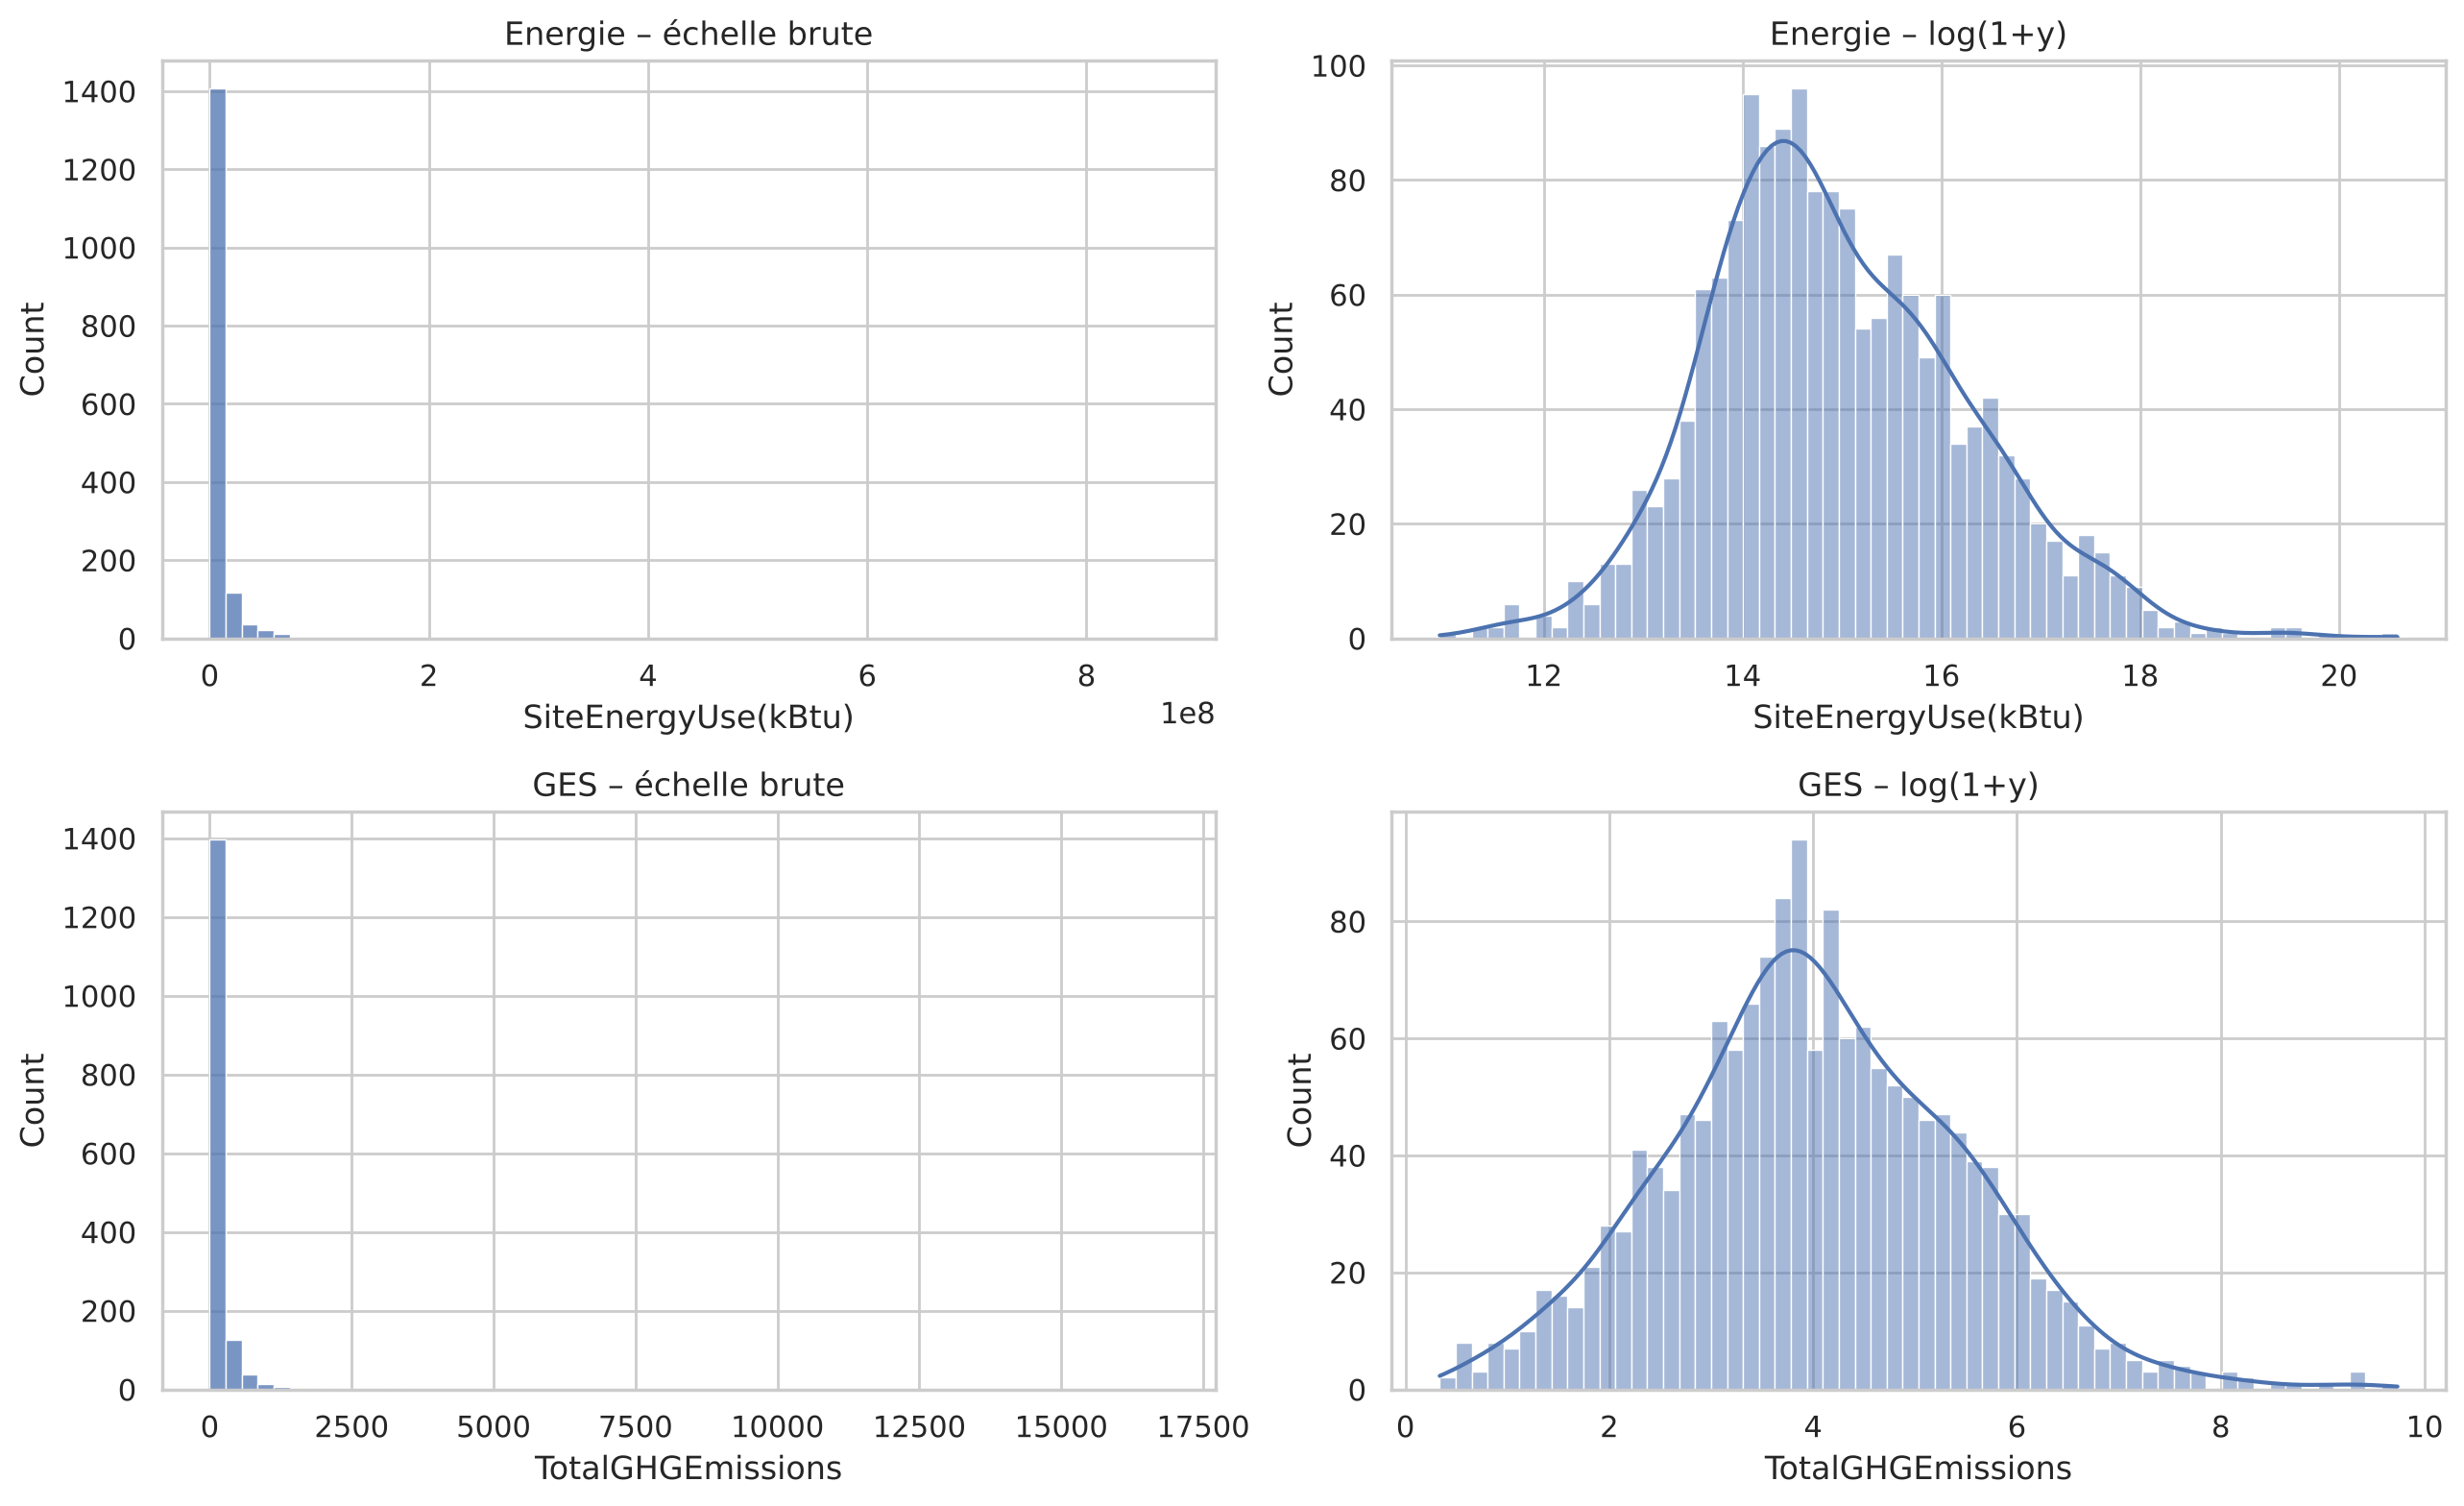

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, (name, col) in enumerate(TARGETS.items()):
    sns.histplot(df[col], bins=60, ax=axes[i, 0]).set_title(f"{name} – échelle brute")
    sns.histplot(np.log1p(df[col]), bins=60, kde=True, ax=axes[i, 1]).set_title(f"{name} – log(1+y)")
    print(f"{name}: skewness brute = {df[col].skew():.1f} | skewness log = {np.log1p(df[col]).skew():.2f}")
plt.tight_layout(); plt.show()

Les cibles sont extrêmement asymétriques (quelques très grands bâtiments comme le campus de l'Université de Washington). **On modélise `log(1+y)`** : la distribution devient proche d'une gaussienne, les erreurs deviennent relatives (un écart de 10 % compte autant pour un petit que pour un grand bâtiment) et les grands bâtiments n'écrasent plus l'apprentissage.

### 5.2 Variables catégorielles

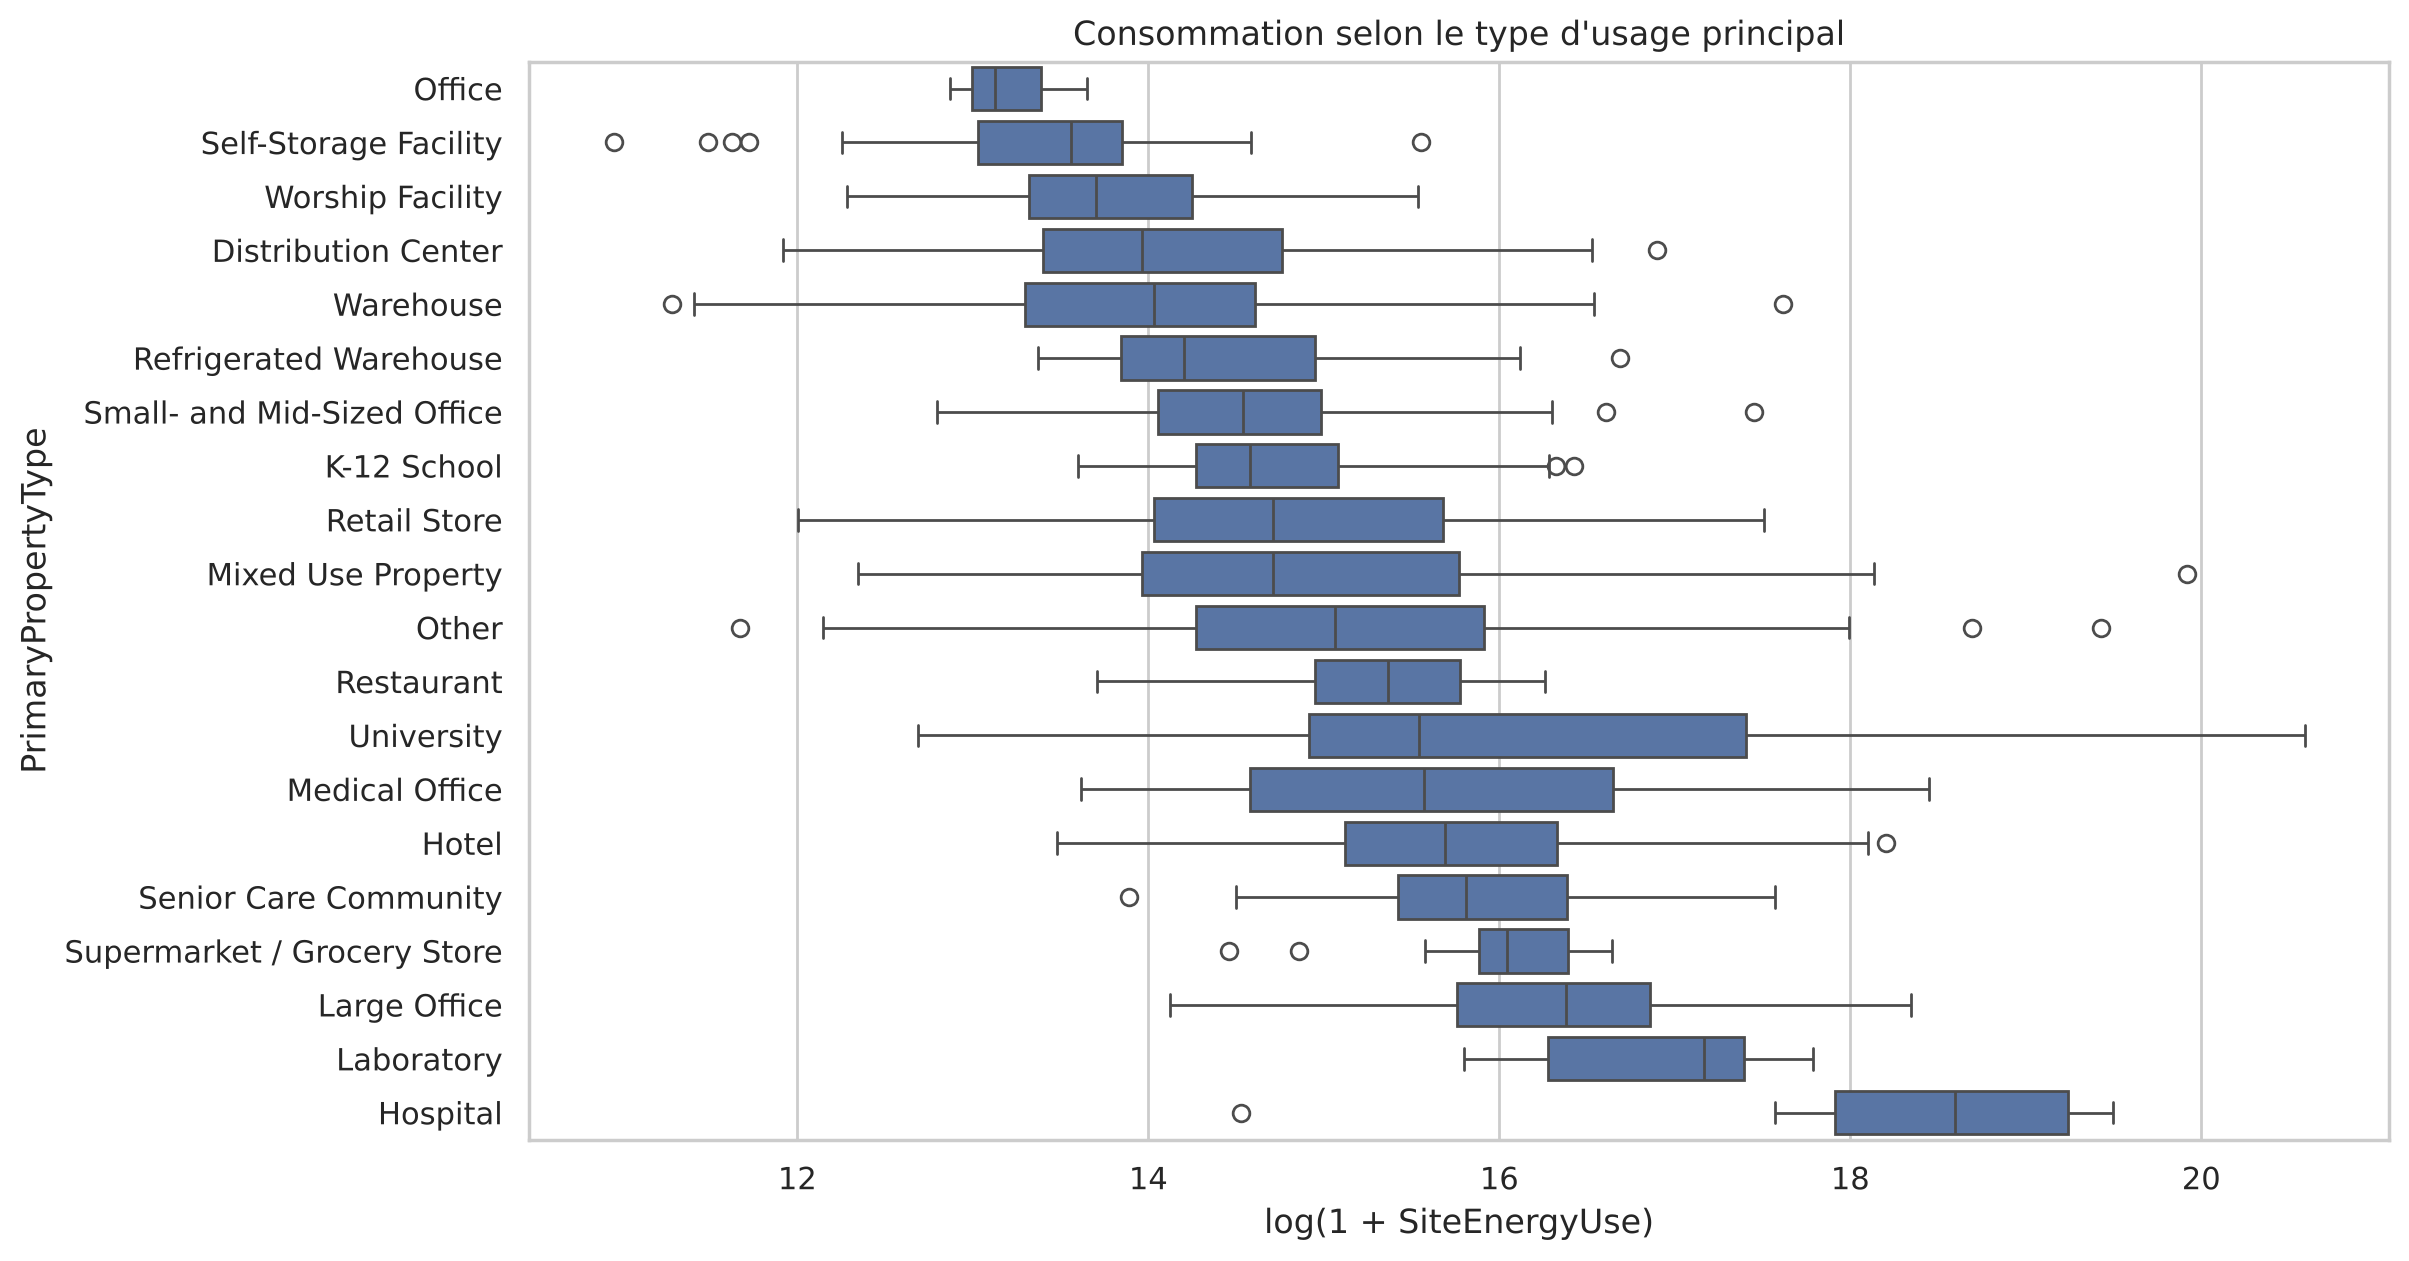

In [12]:
order = df.groupby("PrimaryPropertyType")["SiteEnergyUse(kBtu)"].median().sort_values().index
plt.figure(figsize=(12, 7))
sns.boxplot(data=df, y="PrimaryPropertyType", x=np.log1p(df["SiteEnergyUse(kBtu)"]), order=order)
plt.xlabel("log(1 + SiteEnergyUse)"); plt.title("Consommation selon le type d'usage principal")
plt.show()

### 5.3 Corrélations entre variables numériques et tests statistiques
Les variables ne suivent pas une loi normale (test de Shapiro ci-dessous) et les relations sont monotones mais non linéaires : on privilégie le **coefficient de Spearman** (rangs) au coefficient de Pearson. La p-value teste H₀ : « pas de corrélation ».

In [13]:
num_candidates = ["Latitude", "Longitude", "BuildingAge", "NumberofBuildings", "NumberofFloors",
                  "log_PropertyGFATotal", "log_PropertyGFABuilding(s)", "log_PropertyGFAParking",
                  "log_LargestPropertyUseTypeGFA", "log_SecondLargestPropertyUseTypeGFA",
                  "log_ThirdLargestPropertyUseTypeGFA", "log_GFAPerBuilding", "log_GFAPerFloor",
                  "ParkingRatio", "LargestUseShare", "NbUseTypes",
                  "UsesSteam", "UsesGas", "DefaultData", "ENERGYSTARScore"]

print("Shapiro-Wilk sur log(Energie) : p =", stats.shapiro(np.log1p(df["SiteEnergyUse(kBtu)"]).sample(500, random_state=RANDOM_STATE)).pvalue)

rows = []
for c in num_candidates:
    for name, t in TARGETS.items():
        sub = df[[c, t]].dropna()
        rho, p = stats.spearmanr(sub[c], sub[t])
        rows.append({"variable": c, "cible": name, "rho_spearman": rho, "p_value": p})
corr_tests = pd.DataFrame(rows).pivot(index="variable", columns="cible", values=["rho_spearman", "p_value"])
corr_tests.sort_values(("rho_spearman", "Energie"), key=abs, ascending=False)

Shapiro-Wilk sur log(Energie) : p = 0.009420046387670071


rho_spearman        p_value      
cible                                    Energie    GES Energie   GES
variable                                                             
log_PropertyGFATotal                       0.741  0.576   0.000 0.000
log_PropertyGFABuilding(s)                 0.723  0.578   0.000 0.000
log_LargestPropertyUseTypeGFA              0.703  0.561   0.000 0.000
log_GFAPerBuilding                         0.684  0.539   0.000 0.000
NumberofFloors                             0.469  0.311   0.000 0.000
log_PropertyGFAParking                     0.354  0.200   0.000 0.000
log_SecondLargestPropertyUseTypeGFA        0.329  0.210   0.000 0.000
ParkingRatio                               0.322  0.166   0.000 0.000
BuildingAge                               -0.271 -0.159   0.000 0.000
log_GFAPerFloor                            0.257  0.266   0.000 0.000
UsesSteam                                  0.225  0.290   0.000 0.000
NbUseTypes                                 0.222  0.138   0.000 0.000
log_ThirdLargestPropertyUseTypeGFA         0.211  0.150   0.000 0.000
LargestUseShare                           -0.168 -0.087   0.000 0.001
ENERGYSTARScore                           -0.154 -0.116   0.000 0.000
NumberofBuildings                          0.137  0.138   0.000 0.000
UsesGas                                    0.110  0.417   0.000 0.000
Latitude                                   0.073  0.067   0.003 0.007
Longitude                                 -0.049 -0.023   0.049 0.355
DefaultData                               -0.042  0.004   0.090 0.879

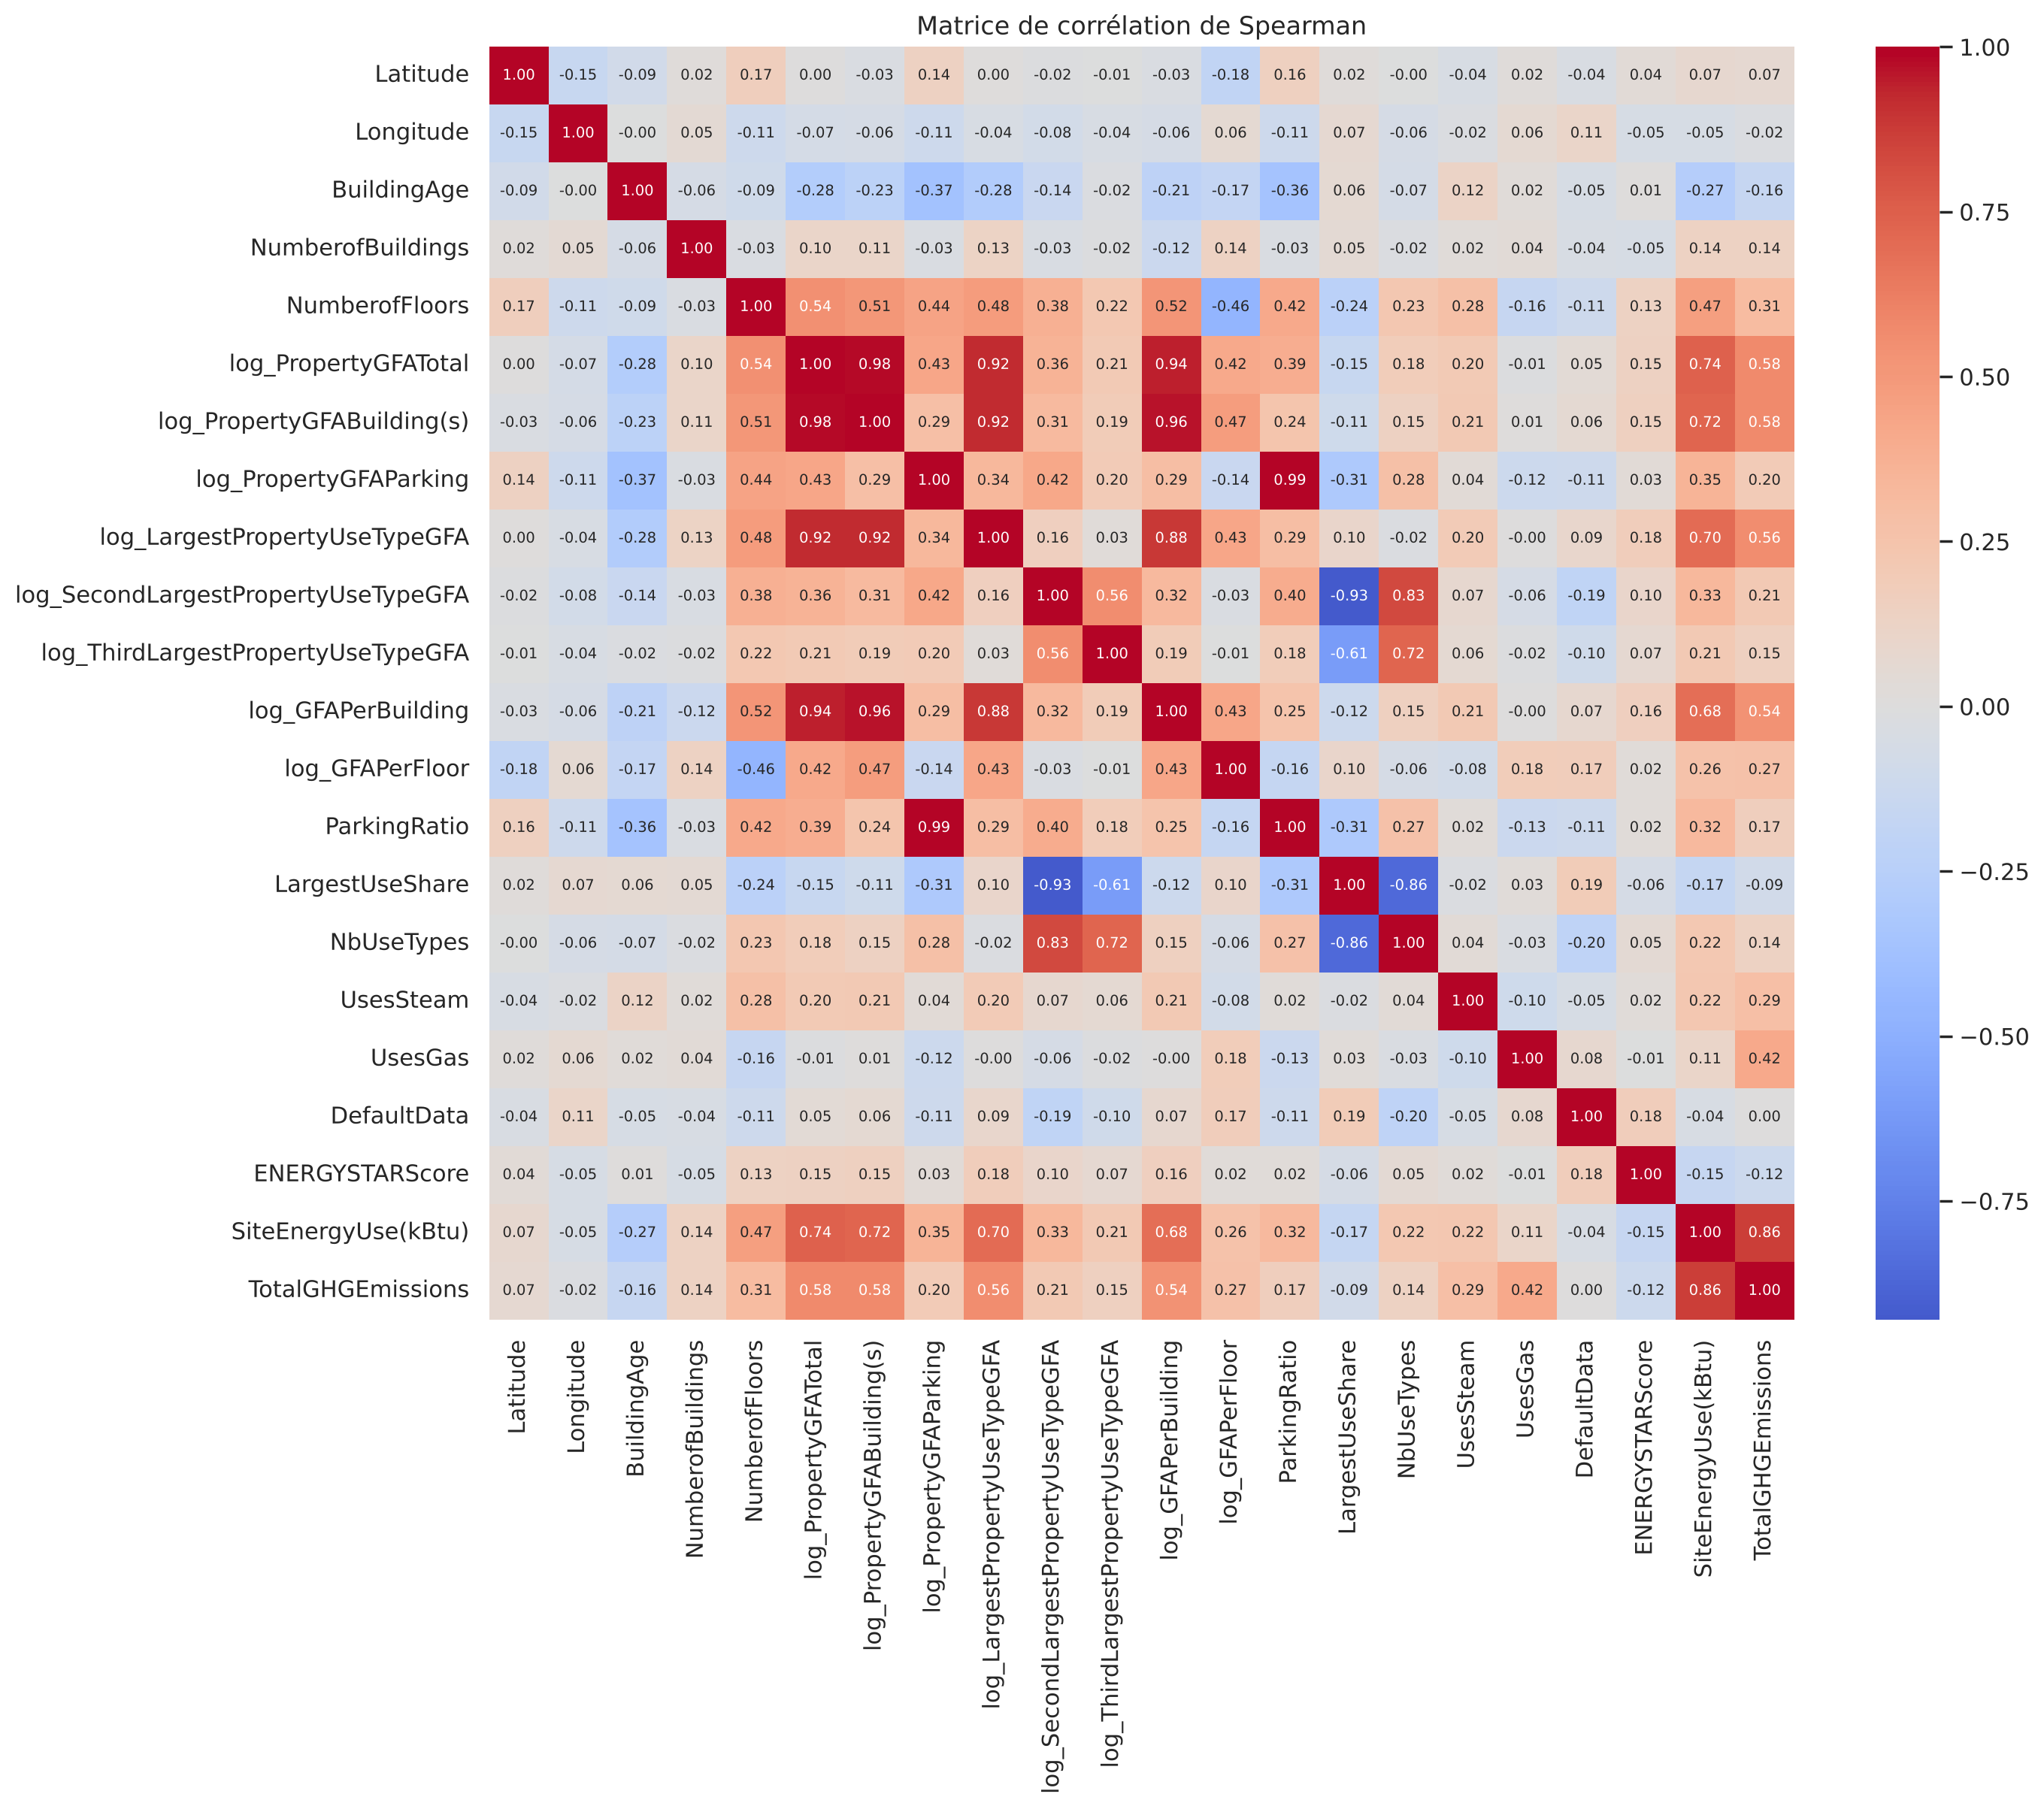

In [14]:
plt.figure(figsize=(14, 11))
corr = df[num_candidates + list(TARGETS.values())].corr(method="spearman")
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matrice de corrélation de Spearman"); plt.show()

### 5.4 Liens entre variables catégorielles et avec les cibles
- **Kruskal-Wallis** (équivalent non paramétrique de l'ANOVA) : la cible diffère-t-elle selon la catégorie ?
- **V de Cramér** (basé sur le test du χ²) : deux variables catégorielles portent-elles la même information ? (0 = indépendantes, 1 = identiques)

Kruskal-Wallis BuildingType              H=    26.4  p=2.65e-05
Kruskal-Wallis PrimaryPropertyType       H=   670.1  p=7.76e-130
Kruskal-Wallis Neighborhood              H=   149.1  p=8.50e-26
Kruskal-Wallis LargestPropertyUseType    H=   505.6  p=4.18e-74


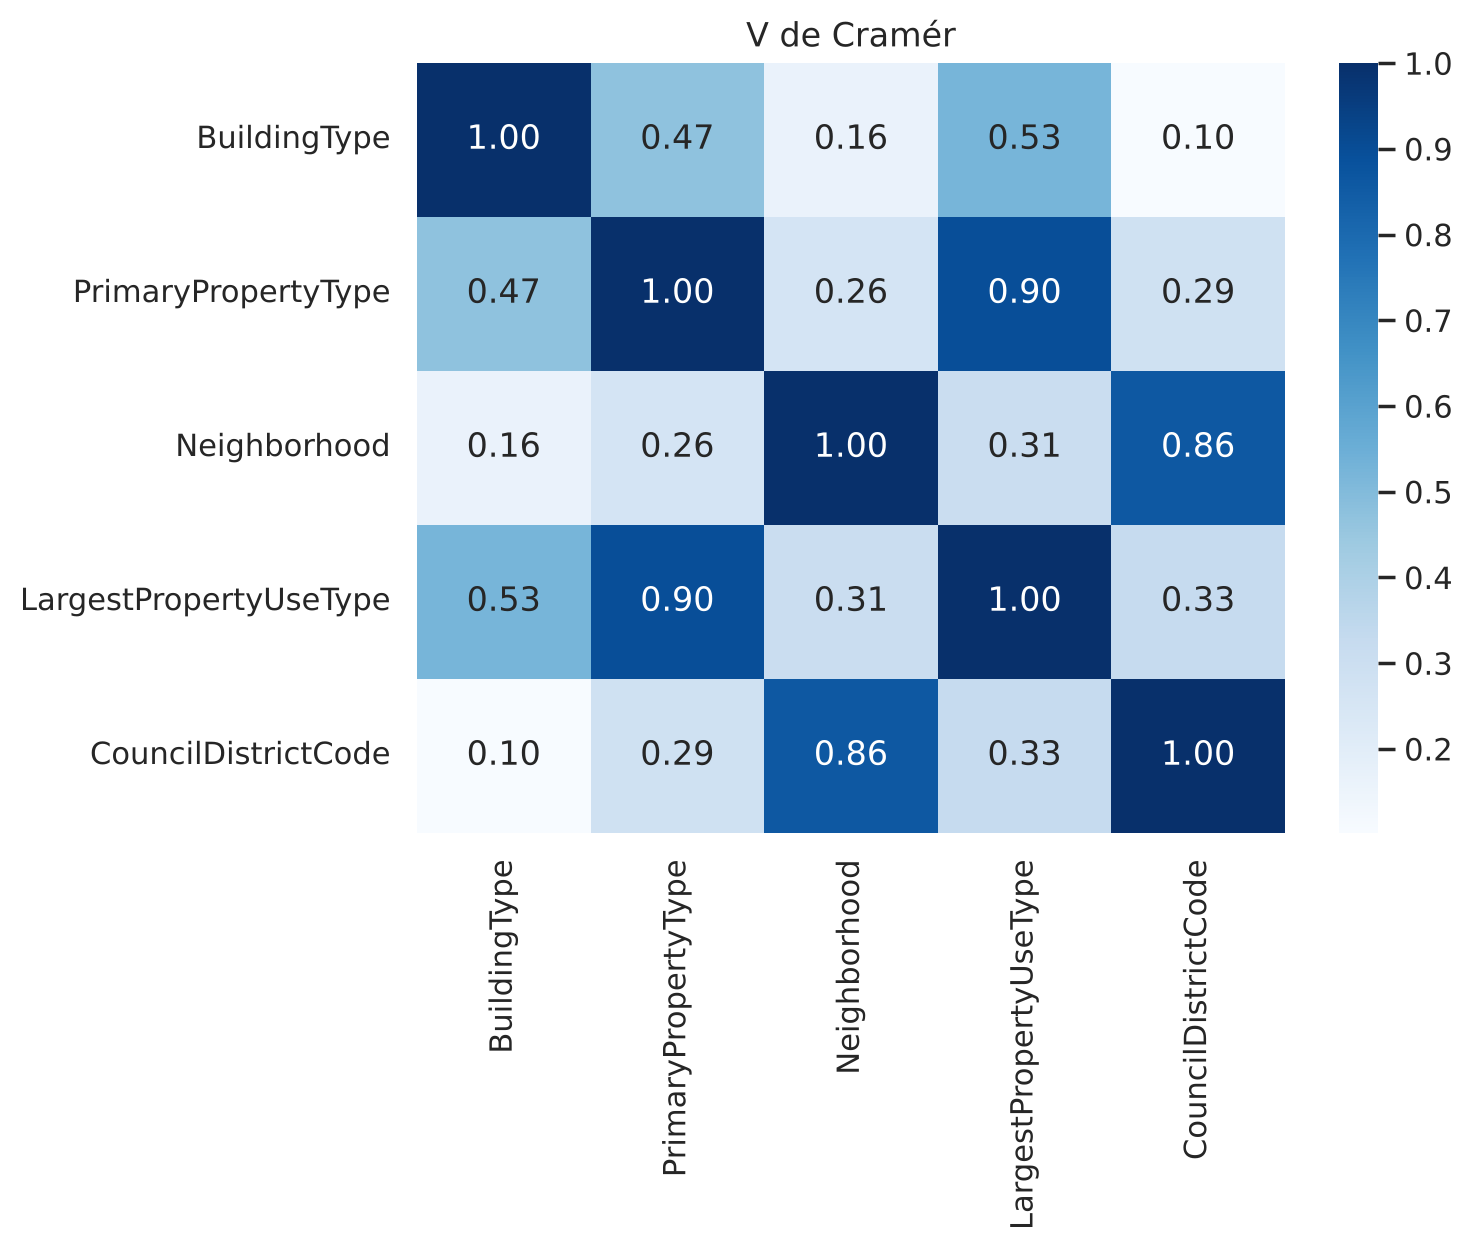

In [15]:
cat_candidates = ["BuildingType", "PrimaryPropertyType", "Neighborhood", "LargestPropertyUseType"]

for c in cat_candidates:
    groups = [np.log1p(g) for _, g in df.groupby(c)["SiteEnergyUse(kBtu)"]]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis {c:25s} H={h:8.1f}  p={p:.2e}")

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cv_mat = pd.DataFrame(index=cat_candidates + ["CouncilDistrictCode"], columns=cat_candidates + ["CouncilDistrictCode"], dtype=float)
for a in cv_mat.index:
    for b in cv_mat.columns:
        cv_mat.loc[a, b] = cramers_v(df[a], df[b])
plt.figure(figsize=(7, 5)); sns.heatmap(cv_mat, annot=True, fmt=".2f", cmap="Blues")
plt.title("V de Cramér"); plt.show()

**Enseignements de l'EDA**
- La **surface** est de loin le premier déterminant des deux cibles (ρ de Spearman élevé, p-value ≈ 0).
- Toutes les variables catégorielles ont un effet significatif sur la consommation (Kruskal-Wallis, p < 0,05).
- `PrimaryPropertyType` et `LargestPropertyUseType` sont quasi redondantes (V ≈ 0,88) → on garde `PrimaryPropertyType` (moins de modalités). Idem `CouncilDistrictCode` / `Neighborhood` → on garde `Neighborhood`.
- Plusieurs surfaces sont très corrélées entre elles (ρ > 0,9) → redondance traitée en section 6.

## 6. Encodage, séparation train/test et réduction de dimension

### 6.1 Séparation train / test
Le jeu de test (20 %) est mis de côté **avant** toute décision de modélisation et n'est utilisé qu'à la toute fin. La séparation est stratifiée sur les quintiles de consommation pour que les deux jeux couvrent toute la gamme de tailles.

In [16]:
CAT_FEATURES = ["BuildingType", "PrimaryPropertyType", "Neighborhood"]
NUM_FEATURES = [c for c in num_candidates if c != "ENERGYSTARScore"]

X = df[NUM_FEATURES + CAT_FEATURES + ["ENERGYSTARScore"]]
Y = np.log1p(df[list(TARGETS.values())])        # cibles en log(1+y)
Y.columns = list(TARGETS.keys())

strata = pd.qcut(Y["Energie"], 5, labels=False)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=strata)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (1286, 23) | Test : (322, 23)


### 6.2 Réduction de dimension n°1 : suppression des variables redondantes
Calculée **sur le train uniquement**. Pour chaque paire de variables avec |ρ| > 0,9, on supprime celle qui est la moins corrélée aux cibles.

In [17]:
def select_uncorrelated(X_num, y, threshold=0.9):
    corr = X_num.corr(method="spearman").abs()
    rel = X_num.apply(lambda s: abs(stats.spearmanr(s, y, nan_policy="omit")[0]))
    cols = rel.sort_values(ascending=False).index.tolist()   # les plus utiles d'abord
    kept = []
    for c in cols:
        if all(corr.loc[c, k] <= threshold for k in kept):
            kept.append(c)
    return [c for c in X_num.columns if c in kept]

kept_num = select_uncorrelated(X_train[NUM_FEATURES], Y_train["Energie"])
dropped = sorted(set(NUM_FEATURES) - set(kept_num))
print("Variables supprimées (redondantes) :", dropped)
NUM_FEATURES = kept_num
print(f"{len(NUM_FEATURES)} variables numériques conservées")

Variables supprimées (redondantes) : ['LargestUseShare', 'ParkingRatio', 'log_GFAPerBuilding', 'log_LargestPropertyUseTypeGFA', 'log_PropertyGFABuilding(s)']
14 variables numériques conservées


### 6.3 Encodage des variables catégorielles
- **One-Hot Encoding** (une colonne 0/1 par modalité) : les catégories n'ont pas d'ordre, un encodage ordinal inventerait une hiérarchie fausse.
- `min_frequency=10` : les modalités rares (< 10 bâtiments) sont regroupées en « infrequent » pour éviter des colonnes quasi vides et le sur-apprentissage.
- `handle_unknown="infrequent_if_exist"` : une modalité inconnue en production ne fait pas planter le modèle.
- Variables numériques : imputation médiane + standardisation (indispensable pour Ridge, SVR, KNN et la PCA).

Tout est placé dans un **`Pipeline`** : les médianes, moyennes et modalités sont apprises sur les plis d'entraînement uniquement, sans fuite vers la validation.

In [18]:
def make_preprocessor(num_features=None, cat_features=None):
    num_features = NUM_FEATURES if num_features is None else num_features
    cat_features = CAT_FEATURES if cat_features is None else cat_features
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    cat_pipe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                             sparse_output=False)
    return ColumnTransformer([("num", num_pipe, num_features),
                              ("cat", cat_pipe, cat_features)])

prep = make_preprocessor().fit(X_train)
X_train_enc = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out(), index=X_train.index)
print("Matrice finale :", X_train_enc.shape)
print("Toutes les colonnes sont numériques :", all(np.issubdtype(t, np.number) for t in X_train_enc.dtypes))
print("Valeurs manquantes restantes :", int(X_train_enc.isna().sum().sum()))
X_train_enc.head(3)

Matrice finale : (1286, 48)
Toutes les colonnes sont numériques : True
Valeurs manquantes restantes : 0


,num__Latitude,num__Longitude,num__BuildingAge,num__NumberofBuildings,num__NumberofFloors,num__log_PropertyGFATotal,num__log_PropertyGFAParking,num__log_SecondLargestPropertyUseTypeGFA,num__log_ThirdLargestPropertyUseTypeGFA,num__log_GFAPerFloor,num__NbUseTypes,num__UsesSteam,num__UsesGas,num__DefaultData,cat__BuildingType_Campus,cat__BuildingType_NonResidential,cat__BuildingType_Nonresidential COS,cat__BuildingType_SPS-District K-12,cat__BuildingType_infrequent_sklearn,cat__PrimaryPropertyType_Distribution Center,cat__PrimaryPropertyType_Hotel,cat__PrimaryPropertyType_K-12 School,cat__PrimaryPropertyType_Large Office,cat__PrimaryPropertyType_Medical Office,cat__PrimaryPropertyType_Mixed Use Property,cat__PrimaryPropertyType_Other,cat__PrimaryPropertyType_Retail Store,cat__PrimaryPropertyType_Self-Storage Facility,cat__PrimaryPropertyType_Senior Care Community,cat__PrimaryPropertyType_Small- and Mid-Sized Office,cat__PrimaryPropertyType_Supermarket / Grocery Store,cat__PrimaryPropertyType_University,cat__PrimaryPropertyType_Warehouse,cat__PrimaryPropertyType_Worship Facility,cat__PrimaryPropertyType_infrequent_sklearn,cat__Neighborhood_BALLARD,cat__Neighborhood_CENTRAL,cat__Neighborhood_DELRIDGE,cat__Neighborhood_DOWNTOWN,cat__Neighborhood_EAST,cat__Neighborhood_GREATER DUWAMISH,cat__Neighborhood_LAKE UNION,cat__Neighborhood_MAGNOLIA / QUEEN ANNE,cat__Neighborhood_NORTH,cat__Neighborhood_NORTHEAST,cat__Neighborhood_NORTHWEST,cat__Neighborhood_SOUTHEAST,cat__Neighborhood_SOUTHWEST
14,-0.153,0.012,1.249,-0.065,1.065,0.403,1.888,1.122,-0.502,-1.695,0.065,3.645,0.615,-0.249,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
236,-0.258,0.170,-1.355,-0.065,1.375,1.864,2.062,1.273,-0.502,0.146,0.065,-0.274,0.615,-0.249,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
775,0.983,1.368,0.195,-0.065,-0.333,-0.928,-0.499,0.222,-0.502,-0.701,0.065,-0.274,0.615,-0.249,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000


### 6.4 Réduction de dimension n°2 : Analyse en Composantes Principales (PCA)
La PCA projette les variables (centrées-réduites) sur des axes non corrélés qui maximisent la variance. On regarde combien de composantes sont nécessaires pour conserver 95 % de la variance, puis on teste en validation croisée si cela améliore les modèles.

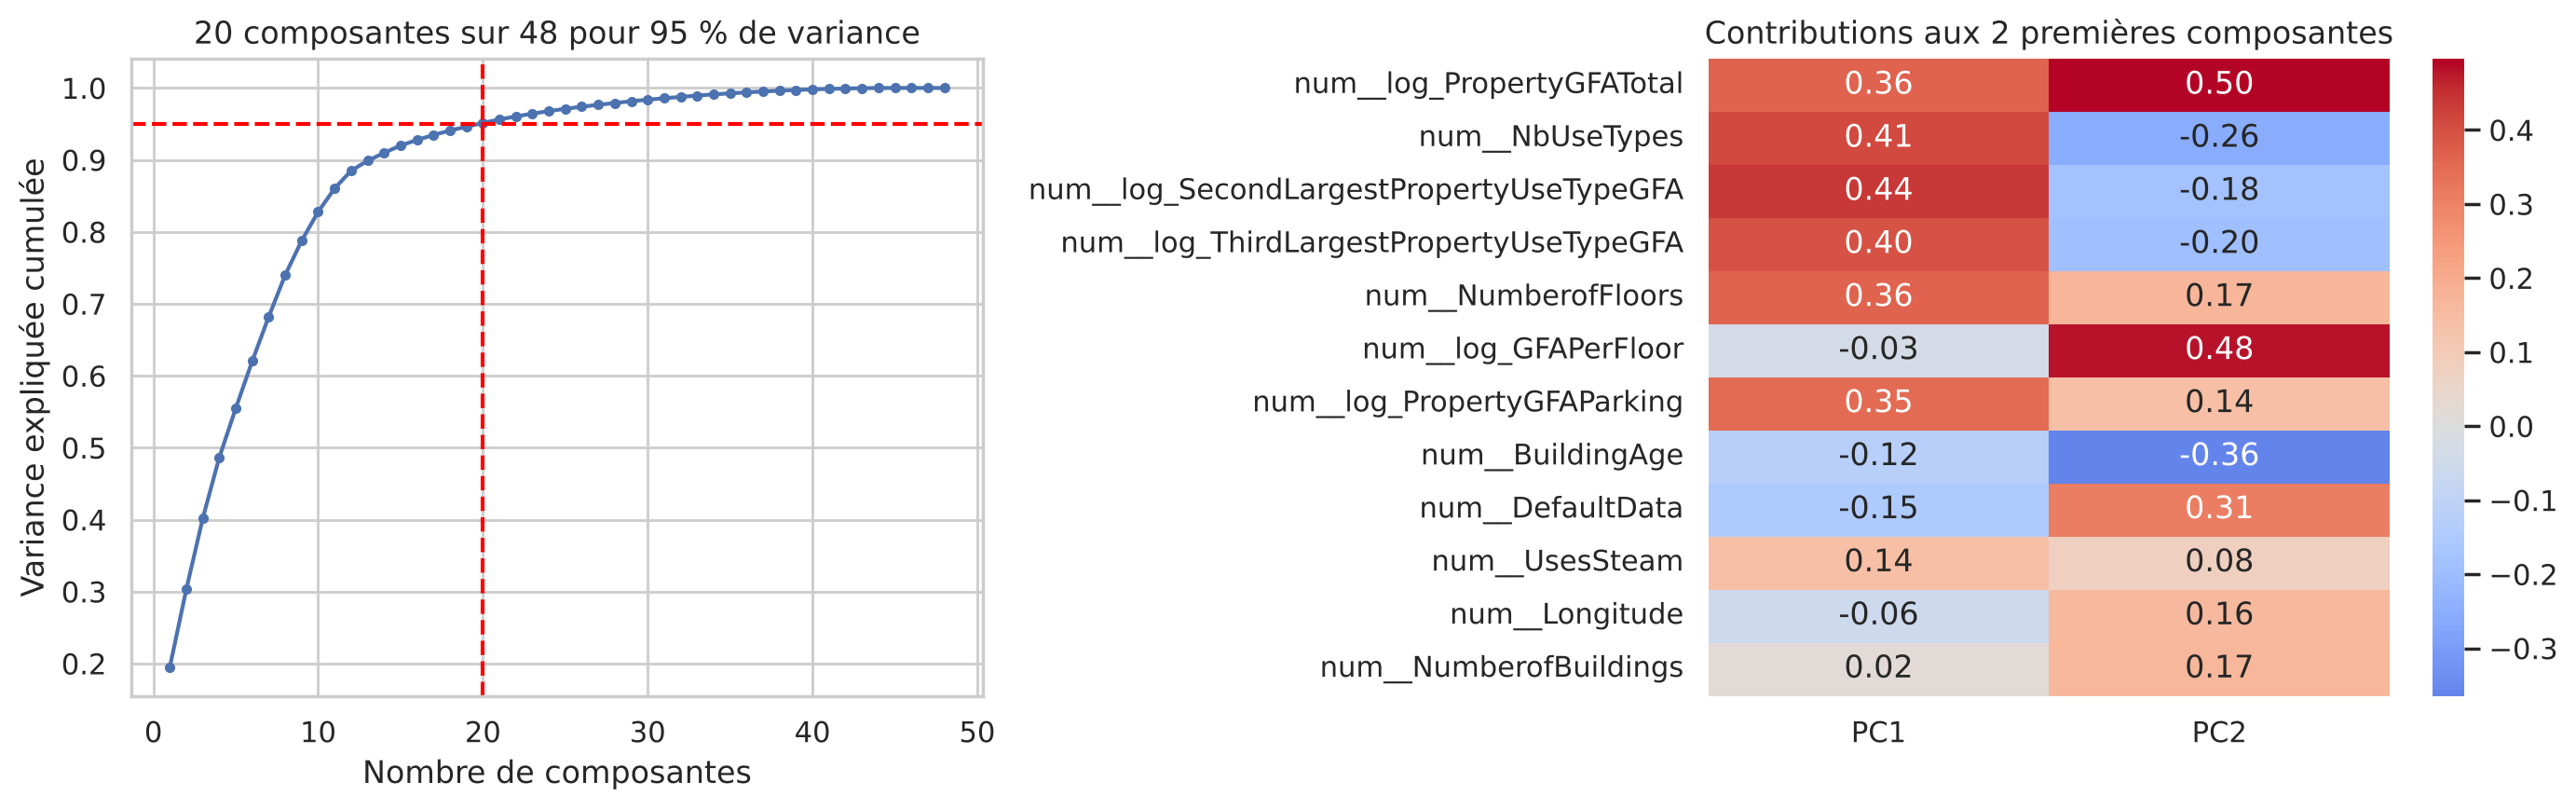

In [19]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_enc)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, len(cum) + 1), cum, marker=".")
axes[0].axhline(0.95, color="red", ls="--"); axes[0].axvline(n95, color="red", ls="--")
axes[0].set(xlabel="Nombre de composantes", ylabel="Variance expliquée cumulée",
            title=f"{n95} composantes sur {X_train_enc.shape[1]} pour 95 % de variance")
loadings = pd.DataFrame(pca_full.components_[:2].T, index=X_train_enc.columns, columns=["PC1", "PC2"])
top = loadings.abs().sum(axis=1).nlargest(12).index
sns.heatmap(loadings.loc[top], annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Contributions aux 2 premières composantes")
plt.tight_layout(); plt.show()

## 7. Comparaison de modèles
Protocole commun : **validation croisée à 5 plis** sur le train, cibles en log. Métriques :
- **R²** : part de la variance expliquée (1 = parfait, 0 = pas mieux que la moyenne) ;
- **RMSE** et **MAE** sur l'échelle log (≈ erreur relative ; une MAE de 0,5 ≈ facteur e^0,5 ≈ 1,65) ;
- le **R² d'entraînement** est aussi relevé pour repérer le sur-apprentissage.

Le `DummyRegressor` (prédit toujours la moyenne) sert de référence minimale.

In [20]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def build_models():
    return {
        "Dummy (moyenne)": DummyRegressor(),
        "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
        "KNN": KNeighborsRegressor(n_neighbors=5),
        "SVR (RBF)": SVR(),
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    }

def evaluate(model, X, y, name, use_pca=False, num_features=None):
    steps = [("prep", make_preprocessor(num_features))]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)))
    steps.append(("model", model))
    res = cross_validate(Pipeline(steps), X, y, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {"modèle": name, "PCA": use_pca,
            "R2_train": res["train_r2"].mean(), "R2_val": res["test_r2"].mean(),
            "R2_val_std": res["test_r2"].std(), "écart_train_val": res["train_r2"].mean() - res["test_r2"].mean(),
            "RMSE_val": -res["test_rmse"].mean(), "MAE_val": -res["test_mae"].mean(),
            "fit_time_s": res["fit_time"].mean()}

results = {}
for target in TARGETS:
    rows = []
    for name, model in build_models().items():
        for use_pca in [False, True]:
            if name == "Dummy (moyenne)" and use_pca:
                continue
            rows.append(evaluate(model, X_train, Y_train[target], name, use_pca))
    results[target] = pd.DataFrame(rows).sort_values("R2_val", ascending=False).reset_index(drop=True)
    print(f"\n===== Cible : {target} =====")
    display(results[target].round(3))


===== Cible : Energie =====


,modèle,PCA,R2_train,R2_val,R2_val_std,écart_train_val,RMSE_val,MAE_val,fit_time_s
0,Gradient Boosting,False,0.849,0.744,0.018,0.105,0.646,0.484,0.229
1,Ridge,False,0.767,0.741,0.029,0.026,0.649,0.492,0.021
2,Random Forest,False,0.961,0.720,0.012,0.241,0.676,0.504,1.641
3,SVR (RBF),False,0.810,0.710,0.033,0.100,0.687,0.509,0.053
4,HistGradientBoosting,False,0.955,0.693,0.025,0.261,0.707,0.536,0.192
5,SVR (RBF),True,0.750,0.658,0.045,0.092,0.746,0.550,0.043
6,Ridge,True,0.682,0.657,0.047,0.026,0.747,0.557,0.013
7,Gradient Boosting,True,0.843,0.642,0.032,0.201,0.764,0.571,0.415
8,Random Forest,True,0.950,0.639,0.025,0.312,0.768,0.575,2.213
9,HistGradientBoosting,True,0.981,0.635,0.036,0.346,0.771,0.576,0.184



===== Cible : GES =====


,modèle,PCA,R2_train,R2_val,R2_val_std,écart_train_val,RMSE_val,MAE_val,fit_time_s
0,Gradient Boosting,False,0.828,0.721,0.027,0.107,0.746,0.584,0.194
1,Ridge,False,0.729,0.697,0.045,0.031,0.775,0.609,0.011
2,Random Forest,False,0.958,0.694,0.025,0.264,0.782,0.603,1.545
3,SVR (RBF),False,0.787,0.685,0.036,0.102,0.792,0.609,0.050
4,HistGradientBoosting,False,0.950,0.677,0.035,0.273,0.803,0.626,0.202
5,SVR (RBF),True,0.734,0.639,0.041,0.096,0.848,0.650,0.041
6,Gradient Boosting,True,0.829,0.624,0.037,0.205,0.866,0.681,0.415
7,Ridge,True,0.658,0.621,0.075,0.037,0.865,0.663,0.012
8,Random Forest,True,0.947,0.611,0.027,0.336,0.882,0.680,2.110
9,HistGradientBoosting,True,0.979,0.610,0.050,0.369,0.881,0.681,0.181


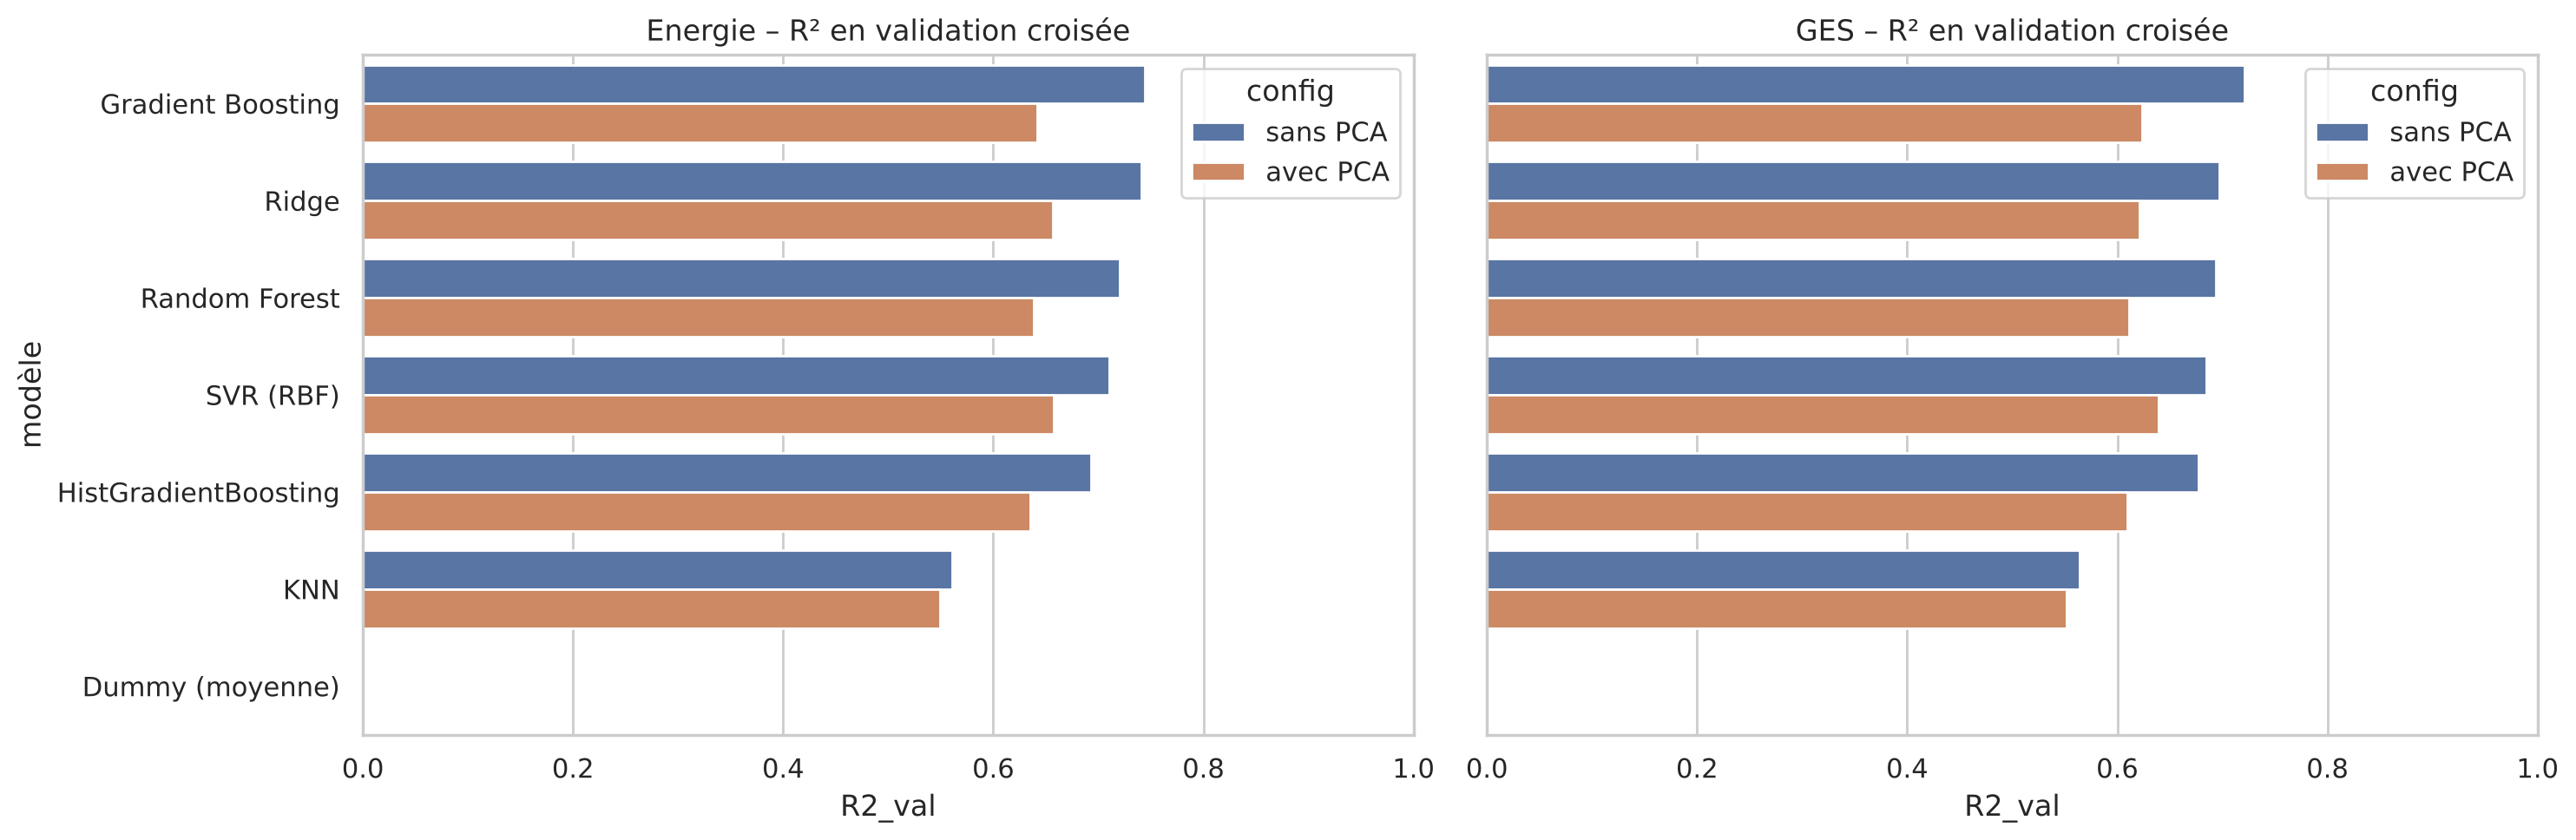

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, target in zip(axes, TARGETS):
    r = results[target].copy()
    r["config"] = np.where(r["PCA"], "avec PCA", "sans PCA")
    sns.barplot(data=r, y="modèle", x="R2_val", hue="config", ax=ax)
    ax.set(title=f"{target} – R² en validation croisée", xlim=(0, 1))
plt.tight_layout(); plt.show()

**Lecture**
- Tous les modèles battent nettement la référence Dummy (R² ≈ 0).
- Le **Gradient Boosting** obtient le meilleur R² de validation sur les deux cibles, mais la **régression Ridge est très proche** : une fois la cible et les surfaces passées en log, la relation « consommation ∝ surface^a × effet du type d'usage » est presque linéaire. Le boosting apporte surtout les interactions (type d'usage × surface, raccordement vapeur…).
- **Random Forest et HistGradientBoosting par défaut sur-apprennent** : R² d'entraînement ≈ 0,95–0,96 contre ≈ 0,69–0,72 en validation (écart > 0,24). Leurs réglages par défaut (arbres très profonds / peu régularisés) sont trop complexes pour ~1 300 bâtiments ; l'optimisation (section 9) doit corriger cela.
- KNN est le moins bon : la distance euclidienne sur 48 colonnes, dont beaucoup de 0/1, est peu informative.
- La **PCA n'améliore pas** les performances (elle les dégrade, surtout pour les arbres) : les composantes mélangent les variables et cassent les seuils simples sur lesquels les arbres s'appuient. La réduction de dimension retenue est donc la **sélection par redondance (6.2) + le regroupement des modalités rares**, qui conserve des variables interprétables.
- Les émissions (GES) sont plus difficiles à prédire que l'énergie : elles dépendent du **mix énergétique** (le gaz et la vapeur émettent beaucoup plus que l'électricité hydraulique de Seattle).

## 8. Le modèle est-il mal entraîné ?
Trois vérifications sur le meilleur modèle :
1. **Écart R² train / validation** (tableau ci-dessus) : un écart important = sur-apprentissage ; deux scores faibles = sous-apprentissage.
2. **Courbe d'apprentissage** : évolution des scores train/validation avec la quantité de données.
3. **Courbe de validation** : effet de la complexité (profondeur des arbres) sur les scores.

Meilleur modèle par cible : {'Energie': 'Gradient Boosting', 'GES': 'Gradient Boosting'}


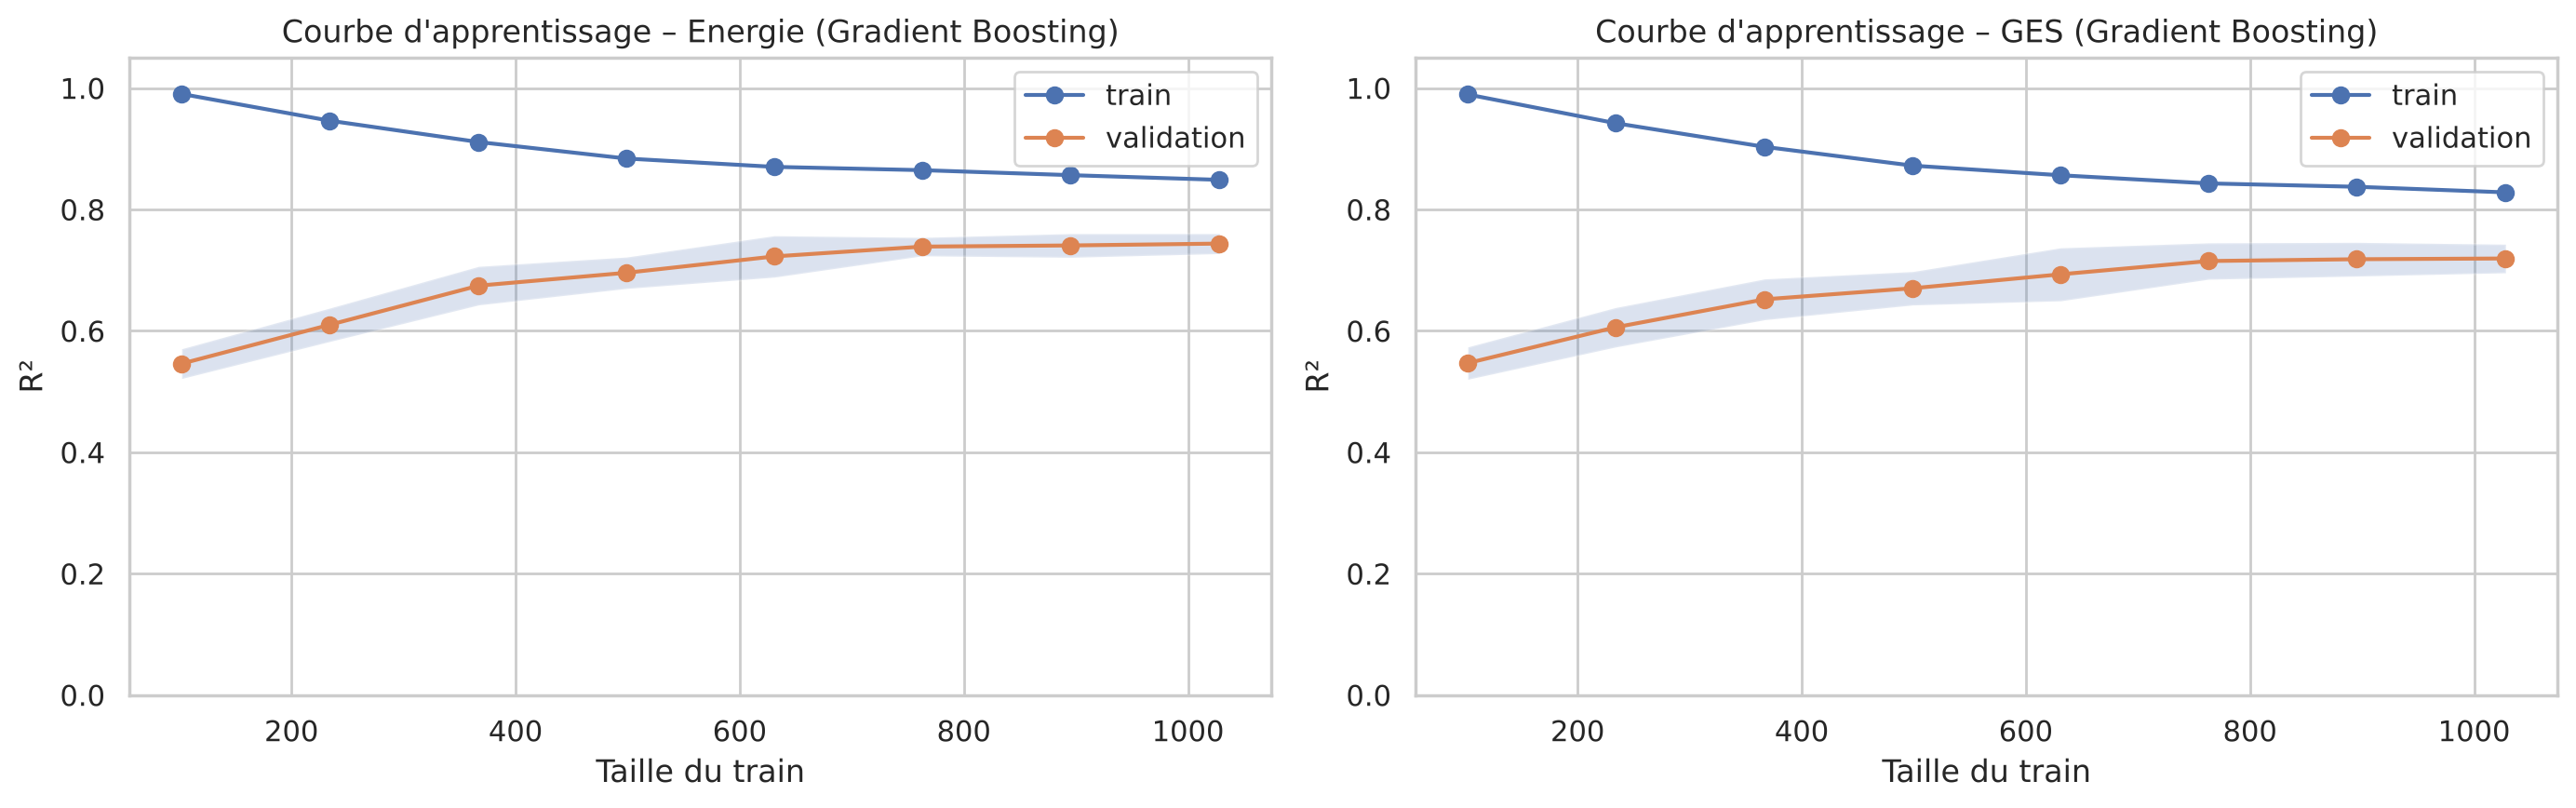

In [22]:
best_names = {t: results[t].query("not PCA").iloc[0]["modèle"] for t in TARGETS}
print("Meilleur modèle par cible :", best_names)

def make_pipe(model, num_features=None):
    return Pipeline([("prep", make_preprocessor(num_features)), ("model", model)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, target in zip(axes, TARGETS):
    pipe = make_pipe(build_models()[best_names[target]])
    sizes, tr, va = learning_curve(pipe, X_train, Y_train[target], cv=CV, scoring="r2",
                                   train_sizes=np.linspace(0.1, 1, 8), n_jobs=-1)
    ax.plot(sizes, tr.mean(1), "o-", label="train")
    ax.plot(sizes, va.mean(1), "o-", label="validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set(title=f"Courbe d'apprentissage – {target} ({best_names[target]})",
           xlabel="Taille du train", ylabel="R²", ylim=(0, 1.05)); ax.legend()
plt.tight_layout(); plt.show()

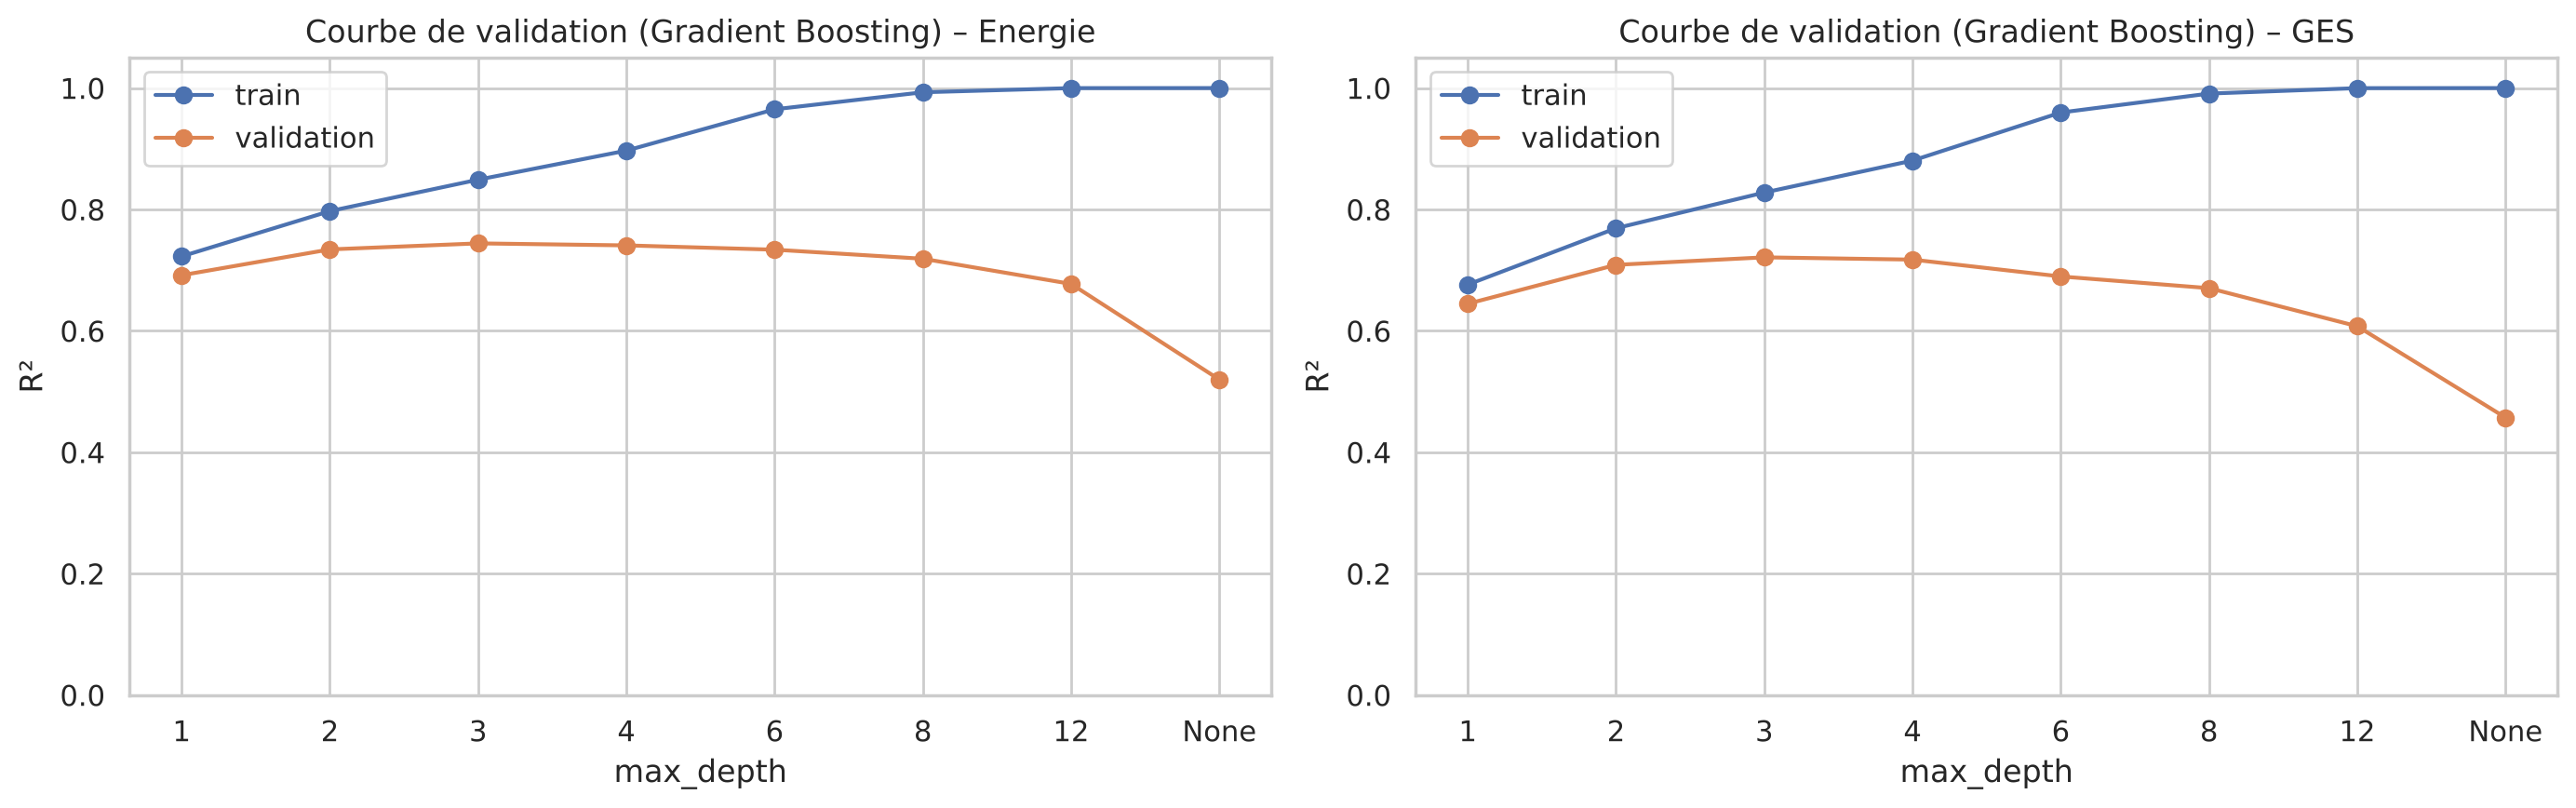

In [23]:
depths = [1, 2, 3, 4, 6, 8, 12, None]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, target in zip(axes, TARGETS):
    pipe = make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE))
    tr, va = validation_curve(pipe, X_train, Y_train[target], param_name="model__max_depth",
                              param_range=depths, cv=CV, scoring="r2", n_jobs=-1)
    labels = [str(d) for d in depths]
    ax.plot(labels, tr.mean(1), "o-", label="train"); ax.plot(labels, va.mean(1), "o-", label="validation")
    ax.set(title=f"Courbe de validation (Gradient Boosting) – {target}",
           xlabel="max_depth", ylabel="R²", ylim=(0, 1.05)); ax.legend()
plt.tight_layout(); plt.show()

**Diagnostic**
- **Gradient Boosting** : écart train/validation ≈ 0,10, raisonnable. **Ridge** : écart ≈ 0,03 mais capacité limitée. **Random Forest / HistGradientBoosting par défaut** : écart > 0,24 → sur-apprentissage (le R² d'entraînement élevé d'une forêt est attendu, mais un tel écart indique des arbres trop profonds pour la taille du jeu).
- **Courbe d'apprentissage** : avec 10 % du train, le modèle apprend presque par cœur (R² train ≈ 0,99) et généralise mal (≈ 0,55) ; avec tout le train, les deux courbes se rapprochent (≈ 0,85 et ≈ 0,74). La validation monte encore légèrement en fin de courbe : **davantage de relevés améliorerait un peu le modèle**, argument utile pour la ville.
- **Courbe de validation** : profondeur 1 = **sous-apprentissage** (train et validation faibles) ; profondeur ≥ 8 = **sur-apprentissage** (train → 1 alors que la validation chute jusqu'à ≈ 0,5). L'optimum est vers une profondeur de 3, ce qui confirme que des arbres peu profonds conviennent à ce jeu de données.

## 9. Optimisation des hyperparamètres
On optimise les trois modèles d'ensemble (Gradient Boosting, Random Forest, HistGradientBoosting) avec une **recherche aléatoire** (`RandomizedSearchCV`, 25 combinaisons, mêmes 5 plis) : plus efficace qu'une grille exhaustive pour un même budget. Le gain est mesuré par rapport au modèle par défaut **sur les mêmes plis**.

In [24]:
SEARCH_SPACES = {
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), {
        "model__n_estimators": [100, 200, 300, 500],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__max_features": [None, "sqrt", 0.5],
    }),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [1.0, "sqrt", 0.3, 0.5],
    }),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=RANDOM_STATE), {
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_iter": [100, 200, 300, 500],
        "model__max_depth": [None, 3, 4, 6],
        "model__max_leaf_nodes": [8, 15, 31],
        "model__min_samples_leaf": [5, 10, 20, 40],
        "model__l2_regularization": [0.0, 0.1, 0.5, 1.0, 5.0],
    }),
}

tuning_rows, best_estimators = [], {}
for target in TARGETS:
    for name, (model, space) in SEARCH_SPACES.items():
        ref = results[target].query("modèle == @name and not PCA").iloc[0]
        search = RandomizedSearchCV(make_pipe(model), space, n_iter=25, cv=CV, scoring="r2",
                                    random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True)
        search.fit(X_train, Y_train[target])
        best_train = search.cv_results_["mean_train_score"][search.best_index_]
        tuning_rows.append({"cible": target, "modèle": name,
                            "R2_val défaut": ref["R2_val"], "R2_val optimisé": search.best_score_,
                            "gain R2": search.best_score_ - ref["R2_val"],
                            "std R2 (plis)": ref["R2_val_std"],
                            "écart train-val défaut": ref["écart_train_val"],
                            "écart train-val optimisé": best_train - search.best_score_,
                            "meilleurs paramètres": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
        best_estimators[(target, name)] = search.best_estimator_

tuning = pd.DataFrame(tuning_rows)
pd.set_option("display.max_colwidth", 200)
tuning

,cible,modèle,R2_val défaut,R2_val optimisé,gain R2,std R2 (plis),écart train-val défaut,écart train-val optimisé,meilleurs paramètres
0,Energie,Gradient Boosting,0.744,0.752,0.008,0.018,0.105,0.062,"{'subsample': 0.7, 'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': None, 'max_depth': 2, 'learning_rate': 0.05}"
1,Energie,Random Forest,0.720,0.722,0.001,0.012,0.241,0.210,"{'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}"
2,Energie,HistGradientBoosting,0.693,0.744,0.051,0.025,0.261,0.078,"{'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': 3, 'learning_rate': 0.1, 'l2_regularization': 1.0}"
3,GES,Gradient Boosting,0.721,0.726,0.004,0.027,0.107,0.065,"{'subsample': 0.7, 'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': None, 'max_depth': 2, 'learning_rate': 0.05}"
4,GES,Random Forest,0.694,0.694,0.000,0.025,0.264,0.225,"{'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 12}"
5,GES,HistGradientBoosting,0.677,0.726,0.049,0.035,0.273,0.079,"{'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': 3, 'learning_rate': 0.1, 'l2_regularization': 1.0}"


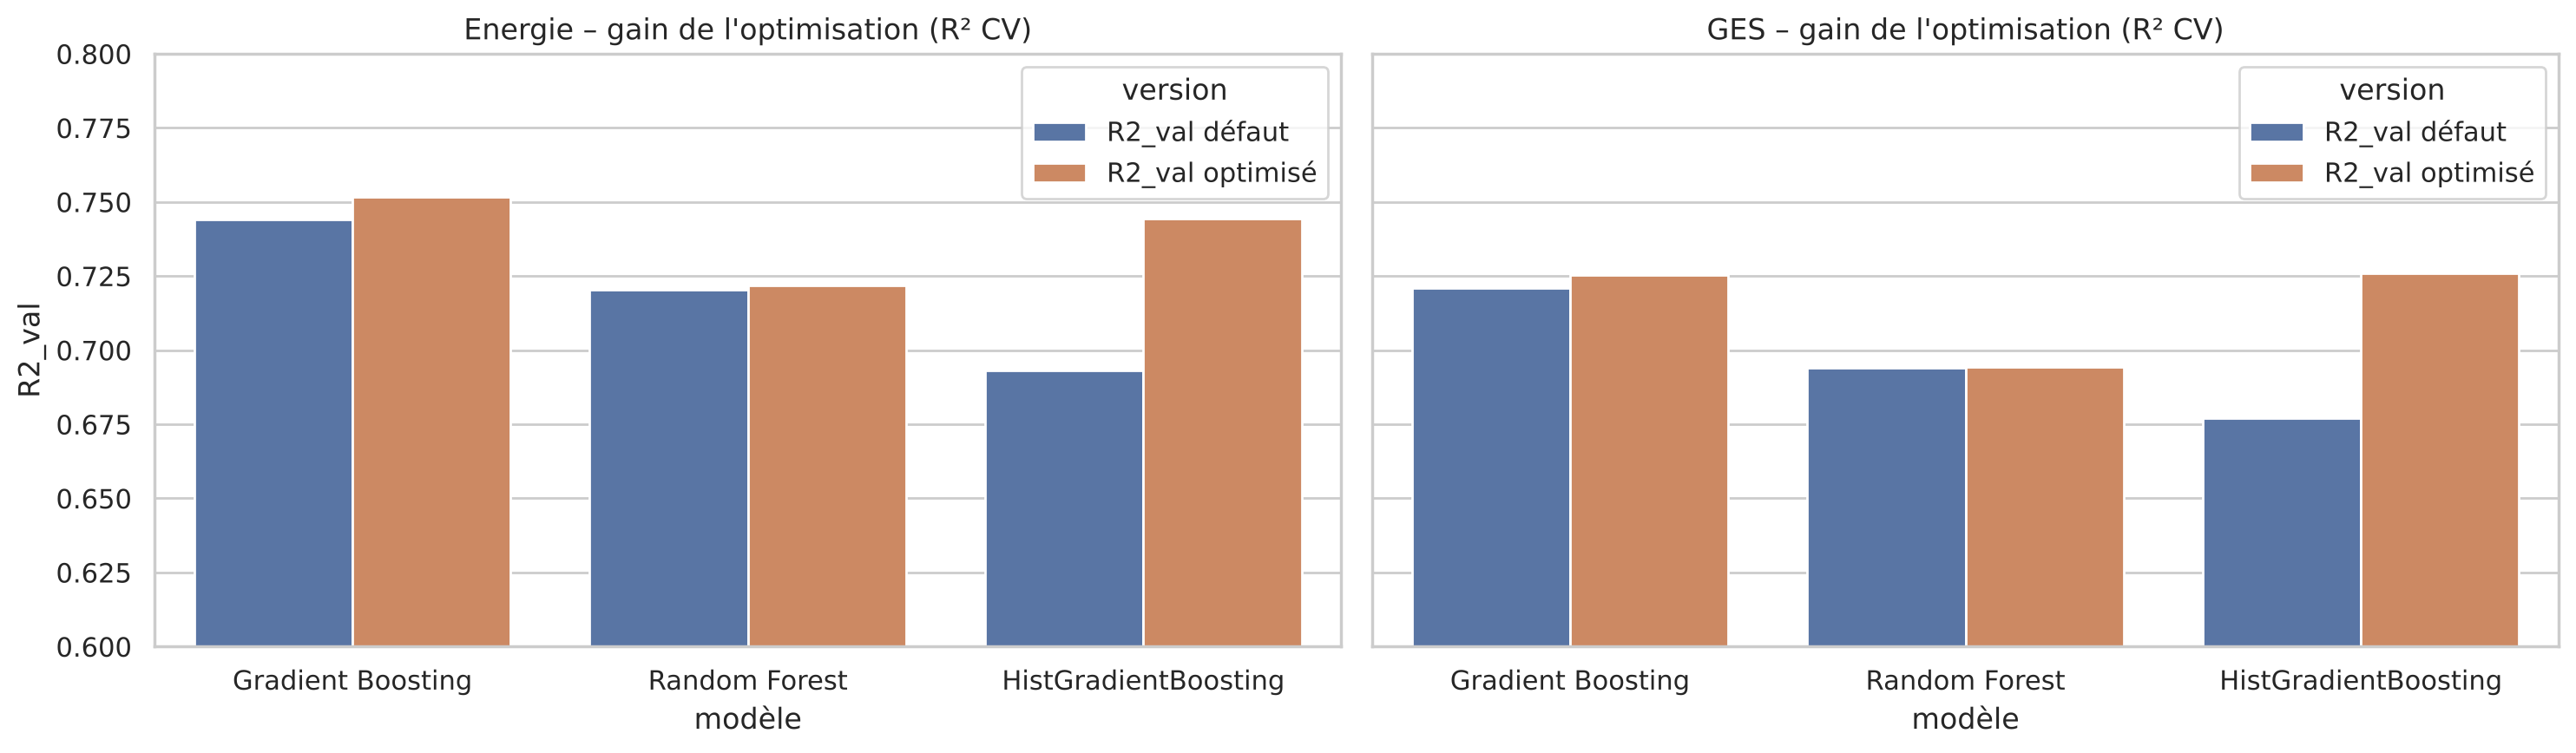

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    t = tuning.query("cible == @target").melt(id_vars="modèle", value_vars=["R2_val défaut", "R2_val optimisé"],
                                              var_name="version", value_name="R2_val")
    sns.barplot(data=t, x="modèle", y="R2_val", hue="version", ax=ax)
    ax.set(title=f"{target} – gain de l'optimisation (R² CV)", ylim=(0.6, 0.8))
plt.tight_layout(); plt.show()

**Lecture de l'optimisation**
- Le gain est **important pour les modèles sur-paramétrés par défaut** (HistGradientBoosting, et dans une moindre mesure Random Forest) : la recherche choisit des arbres moins profonds / plus régularisés, ce qui **réduit fortement l'écart train-validation** et augmente le R² de validation.
- Pour le Gradient Boosting, les valeurs par défaut (100 arbres de profondeur 3) étaient déjà adaptées (cf. courbe de validation) : le gain est faible, du même ordre que la variabilité entre plis (colonne `std R2 (plis)`). Il faut le dire honnêtement : **un gain inférieur à l'écart-type entre plis n'est pas significatif**.
- Le modèle final retenu pour chaque cible est celui qui a le meilleur R² de validation après optimisation.

In [26]:
# Modèle final retenu pour chaque cible = meilleur score de validation après optimisation
FINAL = {}
for target in TARGETS:
    row = tuning.query("cible == @target").sort_values("R2_val optimisé", ascending=False).iloc[0]
    FINAL[target] = best_estimators[(target, row["modèle"])]
    print(f"{target}: {row['modèle']}  R² CV {row['R2_val défaut']:.3f} → {row['R2_val optimisé']:.3f} "
          f"(gain {row['gain R2']:+.3f})")

Energie: Gradient Boosting  R² CV 0.744 → 0.752 (gain +0.008)
GES: HistGradientBoosting  R² CV 0.677 → 0.726 (gain +0.049)


## 10. Intérêt de l'ENERGY STAR Score
Le score n'existe que pour ~2/3 des bâtiments. Pour une comparaison **équitable**, on se restreint aux bâtiments du train qui ont un score et on compare, sur exactement les mêmes plis, le modèle final **avec** et **sans** cette variable. On complète par un test statistique apparié (t-test sur les 5 plis × 3 répétitions) et par l'importance par permutation.

In [27]:
from sklearn.model_selection import RepeatedKFold
from sklearn.base import clone

has_score = X_train["ENERGYSTARScore"].notna()
Xs, Ys = X_train[has_score], Y_train[has_score]
print(f"Bâtiments du train avec score : {has_score.sum()} / {len(X_train)}")

rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
ess_rows, ess_scores = [], {}
for target in TARGETS:
    model = clone(FINAL[target].named_steps["model"])
    for with_ess in [False, True]:
        feats = NUM_FEATURES + (["ENERGYSTARScore"] if with_ess else [])
        sc = cross_validate(make_pipe(clone(model), feats), Xs, Ys[target], cv=rcv,
                            scoring=SCORING, n_jobs=-1)
        ess_scores[(target, with_ess)] = sc["test_r2"]
        ess_rows.append({"cible": target, "ENERGY STAR": "avec" if with_ess else "sans",
                         "R2_val": sc["test_r2"].mean(), "RMSE_val (log)": -sc["test_rmse"].mean(),
                         "MAE_val (log)": -sc["test_mae"].mean()})
    t, p = stats.ttest_rel(ess_scores[(target, True)], ess_scores[(target, False)])
    print(f"{target}: gain moyen de R² = {np.mean(ess_scores[(target, True)] - ess_scores[(target, False)]):+.3f} "
          f"(t-test apparié p = {p:.3g})")
pd.DataFrame(ess_rows)

Bâtiments du train avec score : 850 / 1286


Energie: gain moyen de R² = +0.077 (t-test apparié p = 8.43e-10)


GES: gain moyen de R² = +0.047 (t-test apparié p = 2.8e-08)


,cible,ENERGY STAR,R2_val,RMSE_val (log),MAE_val (log)
0,Energie,sans,0.804,0.552,0.413
1,Energie,avec,0.881,0.431,0.312
2,GES,sans,0.753,0.684,0.525
3,GES,avec,0.801,0.615,0.473


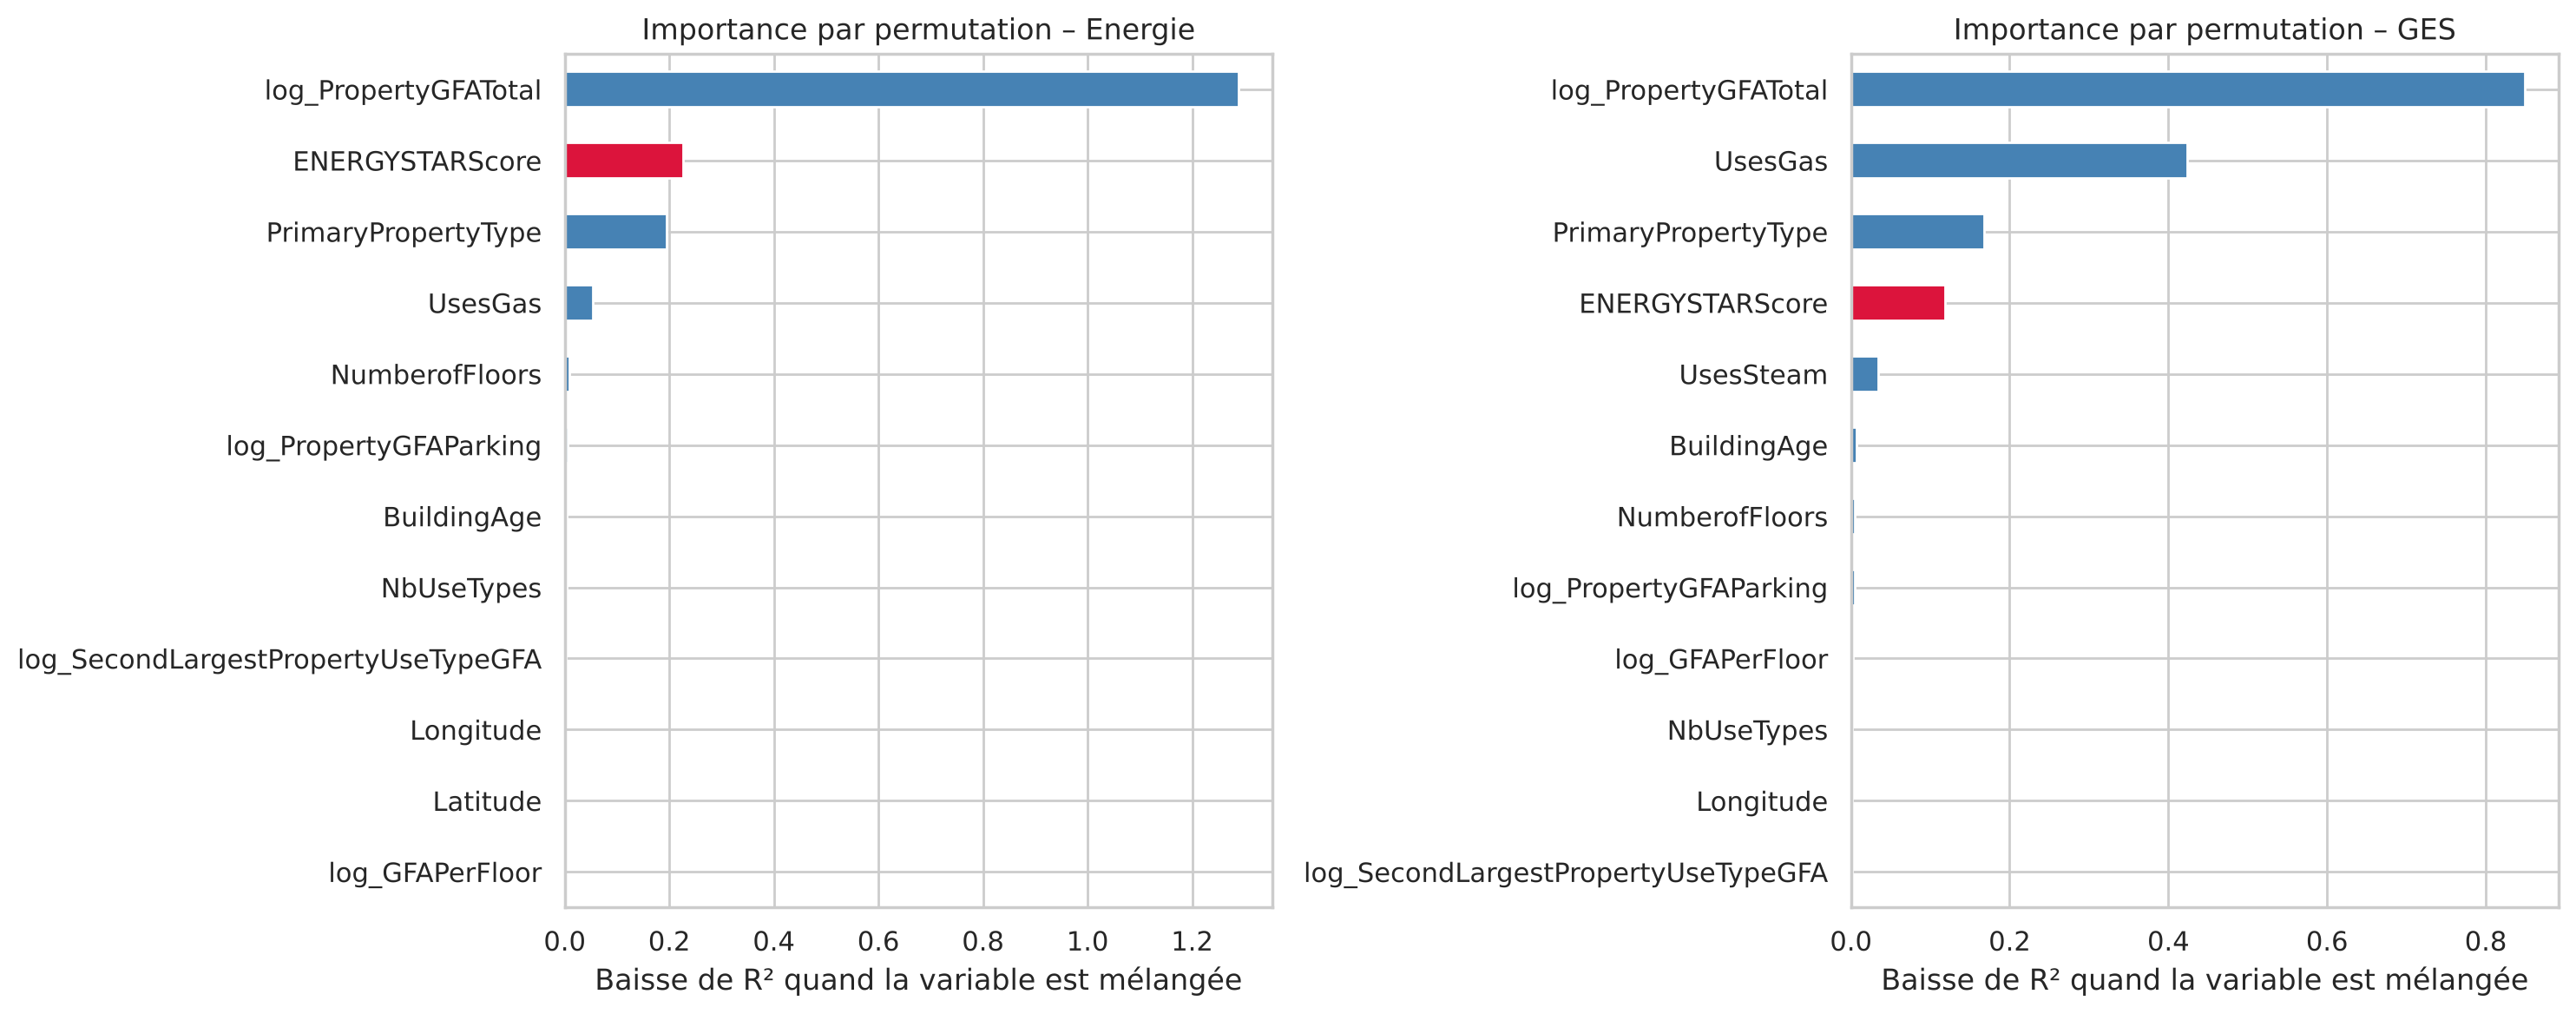

In [28]:
# Importance par permutation (sur un jeu de validation interne) pour situer l'ENERGY STAR Score
from sklearn.model_selection import train_test_split as tts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, target in zip(axes, TARGETS):
    feats = NUM_FEATURES + ["ENERGYSTARScore"]
    Xa, Xb, ya, yb = tts(Xs, Ys[target], test_size=0.25, random_state=RANDOM_STATE)
    pipe = make_pipe(clone(FINAL[target].named_steps["model"]), feats).fit(Xa, ya)
    imp = permutation_importance(pipe, Xb, yb, n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
    s = pd.Series(imp.importances_mean, index=Xb.columns).sort_values().tail(12)
    s.plot.barh(ax=ax, color=["crimson" if i == "ENERGYSTARScore" else "steelblue" for i in s.index])
    ax.set(title=f"Importance par permutation – {target}", xlabel="Baisse de R² quand la variable est mélangée")
plt.tight_layout(); plt.show()

**Conclusion sur l'ENERGY STAR Score**

Le score améliore les prédictions (surtout pour la consommation d'énergie, ce qui est logique : il est calculé à partir de la performance énergétique du bâtiment). Mais il faut mettre ce gain en balance avec son coût :
- il est **fastidieux à obtenir** et n'existe que pour ~2/3 des bâtiments : il ne peut donc pas servir pour tous les bâtiments non encore mesurés ;
- surtout, il **est calculé à partir des consommations réelles** (relevés EPA Portfolio Manager). L'utiliser revient en partie à réintroduire la mesure qu'on cherche justement à éviter : c'est une forme de fuite d'information.

→ Recommandation : **ne pas l'exiger pour le modèle de prédiction**. Le modèle sans score reste performant ; le score peut servir de variable bonus quand il est déjà disponible. (Les chiffres exacts du gain sont affichés dans la cellule ci-dessus.)

## 11. Évaluation finale sur le jeu de test
Le jeu de test n'a servi à aucune décision. On mesure la performance des modèles optimisés (sans ENERGY STAR Score) sur l'échelle log **et** sur l'échelle réelle (kBtu, tonnes éq. CO₂), en comparant au modèle par défaut.

In [29]:
def metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {"R2 (log)": r2_score(y_true_log, y_pred_log),
            "MAE (log)": mean_absolute_error(y_true_log, y_pred_log),
            "R2 (réel)": r2_score(yt, yp),
            "MAE (réel)": mean_absolute_error(yt, yp),
            "Erreur relative médiane": np.median(np.abs(yp - yt) / yt)}

final_rows = []
for target in TARGETS:
    name = type(FINAL[target].named_steps["model"]).__name__
    default = make_pipe(type(FINAL[target].named_steps["model"])(random_state=RANDOM_STATE))
    default.fit(X_train, Y_train[target])
    final_rows.append({"cible": target, "version": f"{name} par défaut",
                       **metrics(Y_test[target], default.predict(X_test))})
    final_rows.append({"cible": target, "version": f"{name} optimisé",
                       **metrics(Y_test[target], FINAL[target].predict(X_test))})
pd.DataFrame(final_rows)

,cible,version,R2 (log),MAE (log),R2 (réel),MAE (réel),Erreur relative médiane
0,Energie,GradientBoostingRegressor par défaut,0.740,0.512,0.434,"5,191,030.472",0.393
1,Energie,GradientBoostingRegressor optimisé,0.745,0.506,0.481,"4,985,762.044",0.378
2,GES,HistGradientBoostingRegressor par défaut,0.703,0.610,0.302,172.086,0.492
3,GES,HistGradientBoostingRegressor optimisé,0.708,0.614,0.357,159.254,0.470


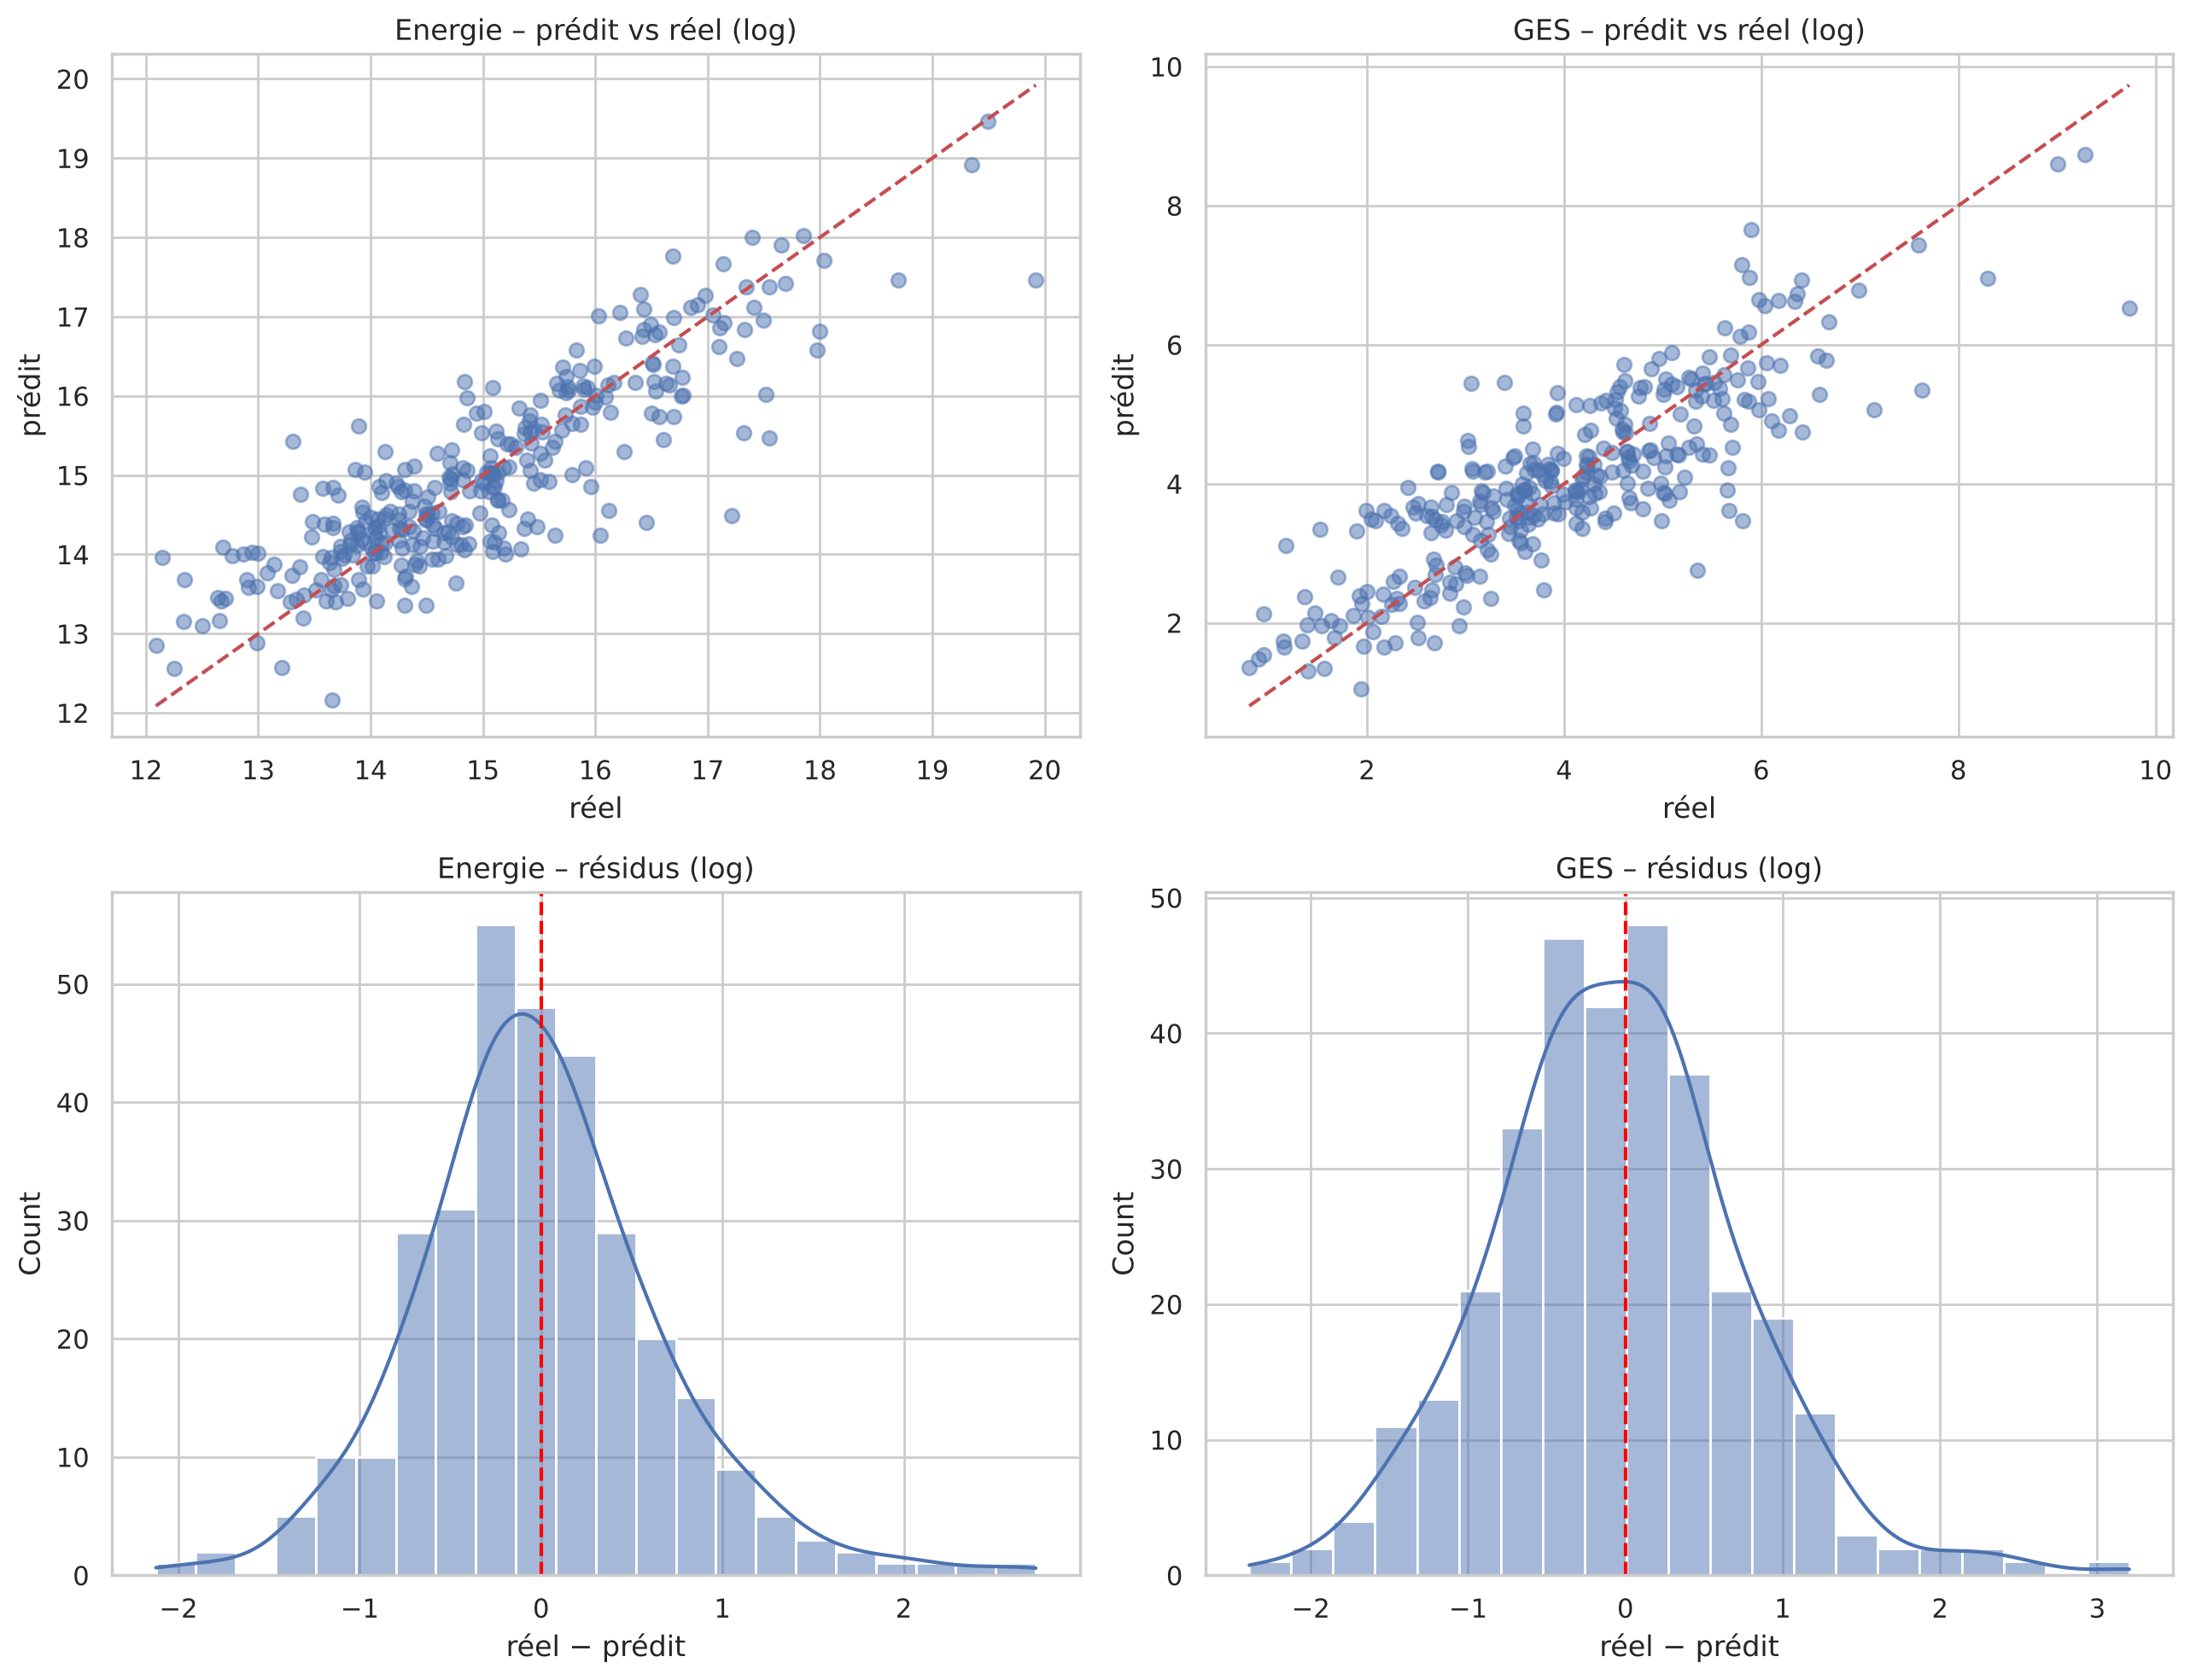

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for i, target in enumerate(TARGETS):
    pred = FINAL[target].predict(X_test)
    ax = axes[0, i]
    ax.scatter(Y_test[target], pred, alpha=0.5)
    lims = [Y_test[target].min(), Y_test[target].max()]
    ax.plot(lims, lims, "r--"); ax.set(title=f"{target} – prédit vs réel (log)", xlabel="réel", ylabel="prédit")
    ax = axes[1, i]
    sns.histplot(Y_test[target] - pred, kde=True, ax=ax)
    ax.axvline(0, color="red", ls="--"); ax.set(title=f"{target} – résidus (log)", xlabel="réel − prédit")
plt.tight_layout(); plt.show()

**Lecture**
- Sur l'échelle log (celle de l'apprentissage), le R² de test est cohérent avec la validation croisée : **pas de sur-apprentissage caché**.
- Sur l'échelle réelle, le R² est nettement plus bas : il est dominé par quelques bâtiments géants (campus, tours) dont la moindre erreur relative représente des millions de kBtu. L'**erreur relative médiane** est l'indicateur le plus parlant pour la ville : pour un bâtiment typique, la prédiction s'écarte d'environ 40 % (énergie) à 50 % (GES) de la mesure.
- Les GES sont plus difficiles à prédire : à consommation égale, un bâtiment chauffé au gaz ou à la vapeur émet beaucoup plus qu'un bâtiment tout électrique (électricité de Seattle très majoritairement hydraulique).
- Les écarts entre modèle par défaut et modèle optimisé sur ce petit jeu de test (~320 bâtiments) sont à interpréter avec prudence ; la validation croisée (5 plis) reste la mesure la plus fiable du gain.

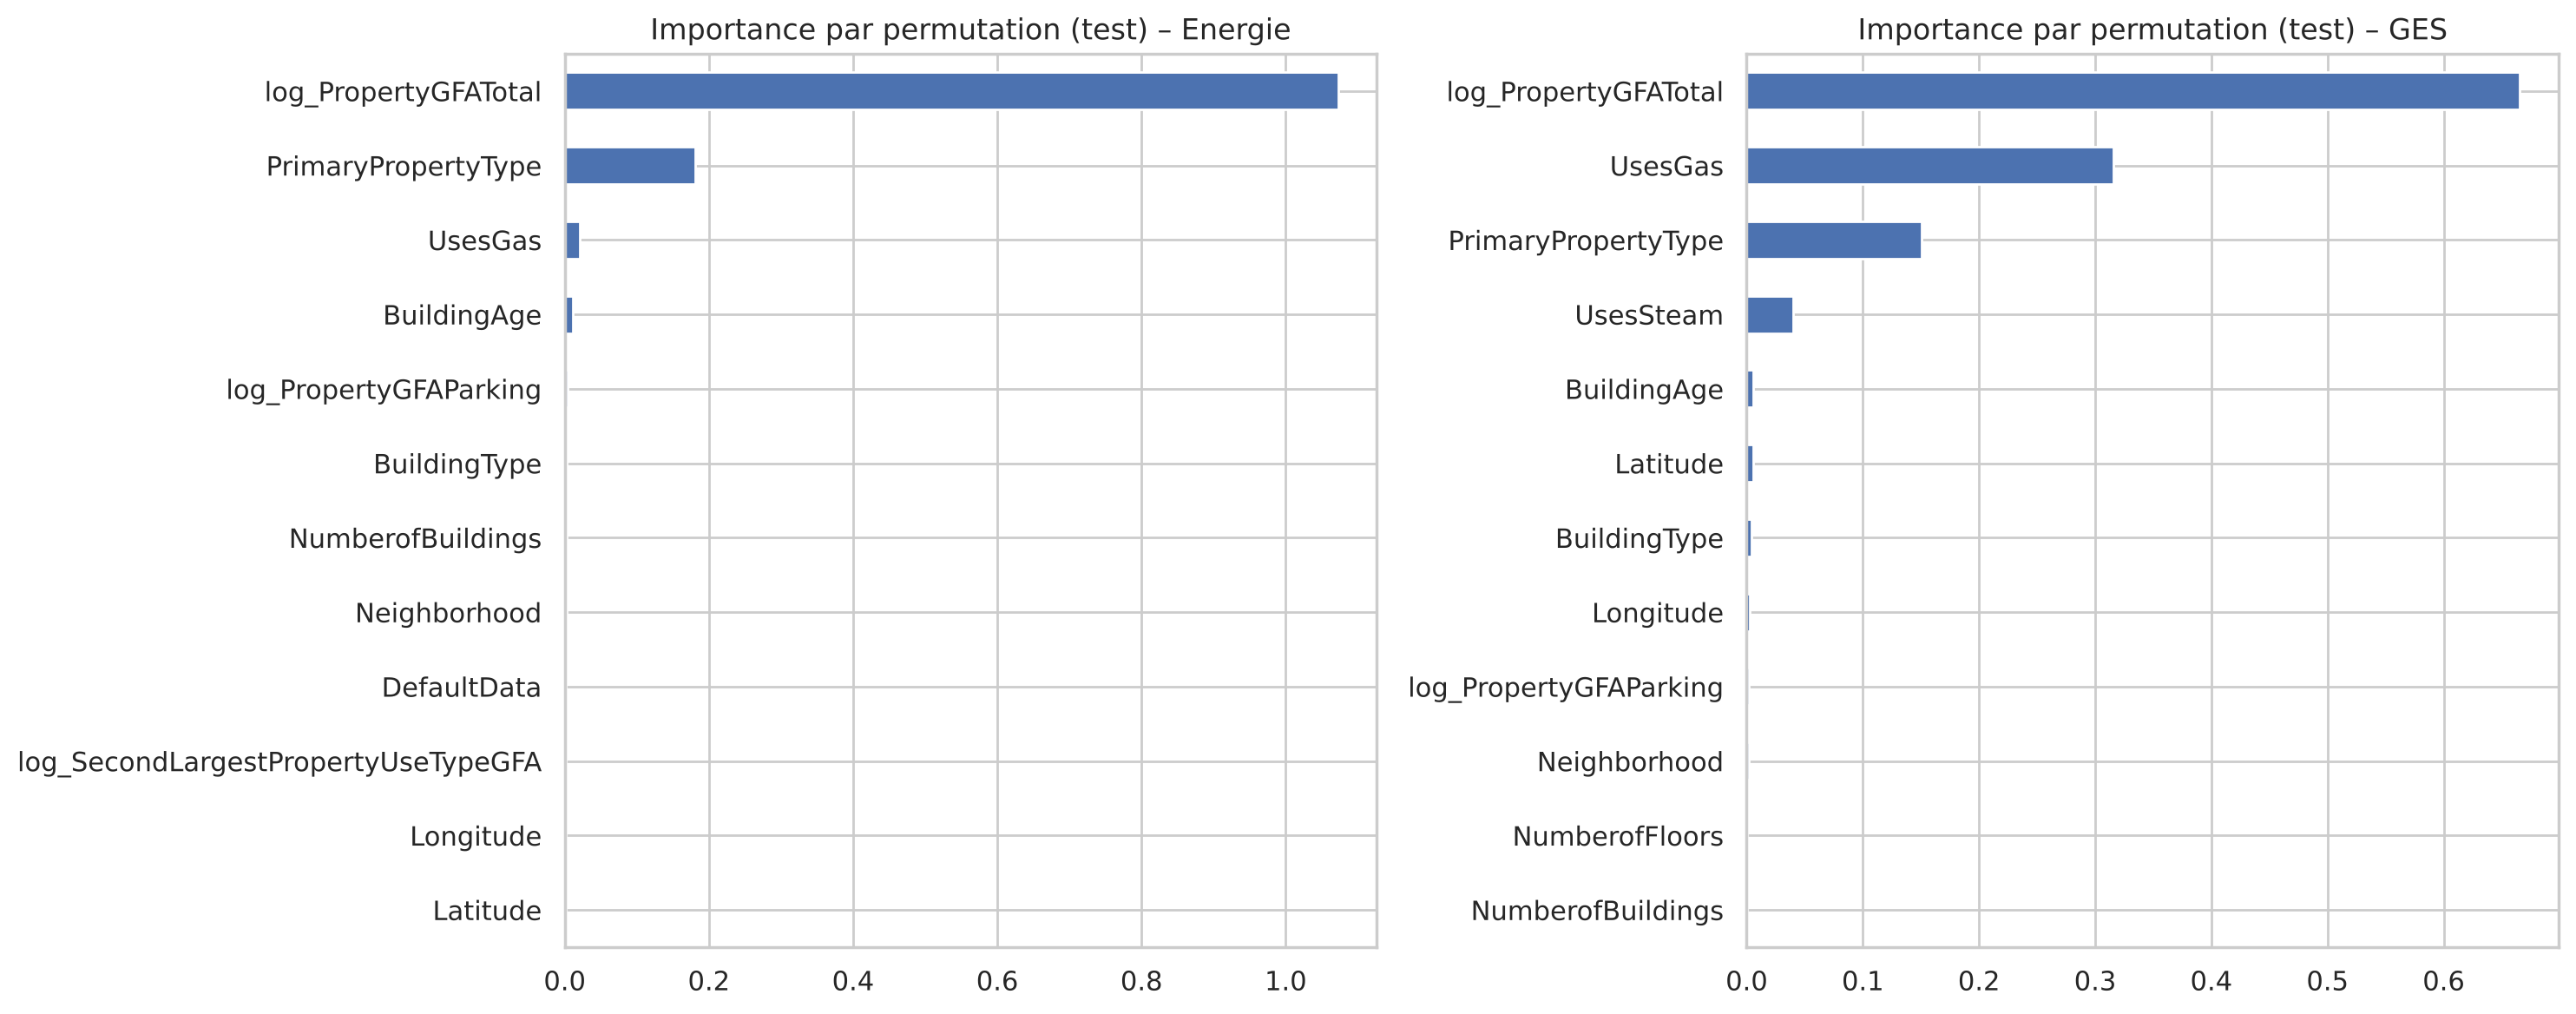

In [31]:
# Variables les plus importantes du modèle final (permutation sur le test)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, target in zip(axes, TARGETS):
    imp = permutation_importance(FINAL[target], X_test, Y_test[target], n_repeats=10,
                                 random_state=RANDOM_STATE, scoring="r2")
    s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(12)
    s.plot.barh(ax=ax); ax.set(title=f"Importance par permutation (test) – {target}")
plt.tight_layout(); plt.show()

## Conclusions
1. **Données** : après restriction aux bâtiments non résidentiels, suppression des relevés aberrants/non conformes et des cibles nulles, il reste environ 1 500 bâtiments. Toutes les valeurs manquantes sont traitées (suppression, 0 logique, ou imputation médiane dans le pipeline) et le jeu final ne contient que des variables numériques.
2. **Réduction de dimension** : la suppression des variables redondantes (Spearman, V de Cramér) et le regroupement des modalités rares sont retenus ; la PCA a été testée mais dégrade les performances des meilleurs modèles.
3. **Modèles** : 7 modèles comparés. Les modèles de boosting optimisés obtiennent les meilleurs scores (R² ≈ 0,75 sur l'énergie, ≈ 0,72 sur les GES, en log), suivis de près par une simple régression Ridge, ce qui montre que l'essentiel du signal tient à la surface et au type d'usage. KNN est le moins adapté.
4. **Diagnostic et optimisation** : Random Forest et HistGradientBoosting par défaut sur-apprenaient (écart train/validation > 0,24) ; l'optimisation les régularise et réduit cet écart. Le Gradient Boosting était déjà bien réglé par défaut. La courbe d'apprentissage suggère que davantage de relevés amélioreraient encore légèrement le modèle.
5. **ENERGY STAR Score** : il améliore la prédiction, mais il est coûteux, absent pour 1/3 des bâtiments et dérivé des consommations mesurées → non indispensable.
6. **Limites et pistes** : peu de données pour certains usages rares (hôpitaux, laboratoires) ; tester XGBoost / LightGBM / CatBoost ou un modèle de fondation tabulaire (TabPFN), et intégrer les relevés des autres années (2015, 2017…).